# BÁO CÁO TỔNG HỢP TOÀN DIỆN DỰ ÁN: DỰ BÁO DOANH THU CHUỖI CÀ PHÊ (`CafeRevenueModelV3`)

**Mục tiêu:** Tổng hợp đầy đủ **Kiến thức nghiệp vụ – Mã nguồn Production (`src/`) – Kiểm toán & Làm sạch Dữ liệu – Phân tích EDA (2024–2026) – Huấn luyện & Kiểm định OOT – Biểu đồ Chẩn đoán & Dự báo Quý 1/2026** trong một tài liệu thực thi khép kín theo **Quy trình 8 bước AI Lifecycle (Chapter 4)**.

| Hạng mục | Thông tin cốt lõi |
| :--- | :--- |
| **Bài toán** | Dự báo doanh thu hàng ngày (đơn vị: **triệu VNĐ**) cho từng cửa hàng trong **Quý 1/2026** (`01/01/2026 – 31/03/2026`) |
| **Quy mô** | `26,632` dòng lịch sử thô $\rightarrow$ `26,500` dòng sạch (`2024–2025`); dự báo `3,869` dòng trên `44` cửa hàng đang hoạt động tại **Hà Nội & TP.HCM** |
| **Thước đo (Metric)** | **RMSLE** (*Root Mean Squared Logarithmic Error*): phạt sai số theo tỷ lệ tương đối thay vì giá trị tuyệt đối |
| **Kiểm định (Validation)** | **Out-of-Time Expanding Window 4 Quý năm 2025** (`Q1, Q2, Q3, Q4/2025`) nhằm loại bỏ hoàn toàn *Data Leakage* chuỗi thời gian |
| **Mô hình tối ưu** | **`CafeRevenueModelV3`** (Stage-1 Weighted Ridge + Dual-Window Empirical Bayes + Kalman AR(1) + Stage-2 HistGBDT + Taylor RMSLE Correction) |

---

### Mục Lục Tài Liệu
1. **Chương 1 — Thu thập Dữ liệu, Định nghĩa Bài toán & Kiến trúc Production (`Step 1`)**
2. **Chương 2 — Kiểm toán Dữ liệu Bẩn & Pipeline Làm sạch Đa bảng (`Step 2a + Step 3 / P1`)**
3. **Chương 3 — Khám phá Dữ liệu Chuyên sâu (EDA) & Quy luật Kinh doanh 2024–2026 (`Step 2b / P2`)**
4. **Chương 4 — Kỹ thuật Đặc trưng & Chiến lược Chia tập Chống Rò rỉ (`Step 4 + Step 5 / P3`)**
5. **Chương 5 — Đấu trường Mô hình, Kiến trúc V3 & Kiểm chứng Overfitting (`Step 6 + Step 7a / P4`)**
6. **Chương 6 — Chẩn đoán Sai số (Residual Diagnostics) & Giải thích Trọng số (`Step 7b`)**
7. **Chương 7 — Dự báo Quý 1/2026, Kiểm tra Submission & Dashboard Điều hành (`Step 8 / P5`)**
8. **Chương 8 — Mô phỏng Kịch bản What-If & Khuyến nghị Chiến lược Kinh doanh**


---
# Chương 1: Thu thập Dữ liệu, Kiến trúc Pipeline & Định nghĩa Bài toán (`Step 1`)

### 1.1. Bối cảnh nghiệp vụ & Thước đo RMSLE
Chuỗi cửa hàng cà phê vận hành `45` điểm bán tại hai thị trường **Hà Nội** và **TP.HCM**, chia theo 5 mô hình địa điểm (`street`, `mall`, `office`, `university`, `residential`). Doanh thu hàng ngày dao động mạnh giữa các mô hình (từ quán khu dân cư ~`7–13` tr/ngày tới quán mặt phố hoặc TTTM có thể đạt `40–70` tr/ngày khi chạy khuyến mãi).

Vì doanh thu lệch phải (*right-skewed*) và chênh lệch quy mô lớn giữa các cửa hàng, cuộc thi đánh giá bằng **RMSLE**:
$$\text{RMSLE}(y, \hat{y}) = \sqrt{\frac{1}{n} \sum_{i=1}^{n} \left(\log(1 + \hat{y}_i) - \log(1 + y_i)\right)^2}$$
- **Ý nghĩa:** Sai số dự báo `10%` ở quán nhỏ `10` tr và quán lớn `50` tr chịu mức phạt tương đương nhau; đồng thời mô hình phải hồi quy trực tiếp trên thang **logarit** thay vì doanh thu gốc để không bị kéo lệch bởi ngày cao điểm.

### 1.2. Giải đáp 2 câu hỏi kiến trúc thường gặp
1. **Vai trò của `test.csv` và `sample_submission.csv`:** Tập `test.csv` cung cấp khóa `(id, date, store_id, is_promo)` cho `3,869` cặp cửa hàng–ngày trong Q1/2026 (đã phản ánh lịch nghỉ Tết và `380` ngày khuyến mãi thực tế). Riêng hàm `build_test_grid_if_missing()` trong `src/cleaning.py` chỉ là cơ chế dự phòng đọc `sample_submission.csv` nếu triển khai ở môi trường thiếu `test.csv`.
2. **Tái sử dụng model khi áp dụng cho dữ liệu mới:** Mô hình `cafe_revenue_model_v3.pkl` học trạng thái theo `store_id`, `city`, lịch sử thời tiết và trạng thái AR(1) đến `max_train_date_`. Do đó khi dùng cho chuỗi cửa hàng **khác bộ dữ liệu** hoặc kéo dài sang quý tiếp theo, ta cần tái huấn luyện qua `CafeRevenueModelV3().fit(...)` bằng chính pipeline chuẩn trong `src/` chứ không mang file `.pkl` cũ áp thẳng sang dữ liệu hoàn toàn xa lạ.

### 1.3. Kiến trúc mã nguồn Production (`src/`)
| Tệp mã nguồn | Trách nhiệm chính |
| :--- | :--- |
| `src/config.py` | Quản lý đường dẫn chuẩn (`TRAIN_PATH`, `TEST_PATH`, `MODELS_DIR`, ...) và các mốc kiểm định `EVAL_QUARTERS` |
| `src/cleaning.py` | Pipeline làm sạch bất biến 5 bảng (`clean_stores`, `clean_weather`, `clean_holidays`, `clean_train`, `clean_test`) |
| `src/features.py` | Tạo đặc trưng nghiệp vụ thống nhất (`enrich_data`, `build_shared_matrix`) dùng cho các mô hình chuẩn và đối chứng |
| `src/baseline_model.py` | `BaselineWeekdayModel`: dự báo bằng trung vị theo `(store_id, dayofweek)` làm chuẩn sàn bắt buộc |
| `src/cafe_model_v3.py` | `CafeRevenueModelV3`: kiến trúc phân tầng 5 lớp tối ưu trực tiếp cho RMSLE |


In [1]:
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# Cấu hình hiển thị bảng & đồ thị hỗ trợ đầy đủ tiếng Việt
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "Segoe UI"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11.5
plt.rcParams["axes.labelsize"] = 10

# Tự động định vị thư mục dự án cafe/ bất kể notebook được mở từ đâu
CAFE_ROOT = None
for candidate in [
    os.path.abspath("."),
    os.path.abspath(".."),
    os.path.abspath("../.."),
    os.path.abspath("data/cafe"),
]:
    if os.path.exists(os.path.join(candidate, "data", "train.csv")) and os.path.exists(
        os.path.join(candidate, "src", "cafe_model_v3.py")
    ):
        CAFE_ROOT = candidate
        break

assert CAFE_ROOT is not None, "Không tìm thấy thư mục dự án data/cafe!"
if CAFE_ROOT not in sys.path:
    sys.path.insert(0, CAFE_ROOT)

from src.config import (
    DATA_DIR,
    MODELS_DIR,
    SUBMISSIONS_DIR,
    EVAL_QUARTERS,
    CAFE_MODEL_V3_PATH,
    BASELINE_MODEL_PATH,
)
from src.cleaning import (
    clean_stores,
    clean_weather,
    clean_holidays,
    clean_train,
    clean_test,
    build_test_grid_if_missing,
)
from src.features import enrich_data, build_shared_matrix
from src.baseline_model import BaselineWeekdayModel
from src.cafe_model_v3 import CafeRevenueModelV3

def rmsle(y_true, y_pred):
    y_t = np.clip(np.asarray(y_true, dtype=float), 0.0, None)
    y_p = np.clip(np.asarray(y_pred, dtype=float), 0.0, None)
    return float(np.sqrt(np.mean((np.log1p(y_p) - np.log1p(y_t)) ** 2)))

# Đọc toàn bộ 6 tệp dữ liệu thô gốc (read-only)
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
stores_raw = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
weather_raw = pd.read_csv(os.path.join(DATA_DIR, "weather.csv"))
holidays_raw = pd.read_csv(os.path.join(DATA_DIR, "holidays.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

print(f"CAFE_ROOT = {CAFE_ROOT}")
print(f"DATA_DIR  = {DATA_DIR}\n")

schema_rows = []
for fname, df_obj in [
    ("train.csv", train_raw),
    ("test.csv", test_raw),
    ("stores.csv", stores_raw),
    ("weather.csv", weather_raw),
    ("holidays.csv", holidays_raw),
    ("sample_submission.csv", sample_sub),
]:
    date_rng = (
        f"{df_obj['date'].min()} -> {df_obj['date'].max()}"
        if "date" in df_obj.columns
        else "-"
    )
    schema_rows.append({
        "Bảng dữ liệu": fname,
        "Số dòng": f"{len(df_obj):,}",
        "Số cột": df_obj.shape[1],
        "Các cột": ", ".join(df_obj.columns),
        "Số ô thiếu (NaN)": int(df_obj.isna().sum().sum()),
        "Phạm vi ngày": date_rng,
    })

display(pd.DataFrame(schema_rows))


CAFE_ROOT = E:\study\AI\test 1\Kaggle_Competition\data\cafe
DATA_DIR  = E:\study\AI\test 1\Kaggle_Competition\data\cafe\data



,Bảng dữ liệu,Số dòng,Số cột,Các cột,Số ô thiếu (NaN),Phạm vi ngày
0,train.csv,"26,632",4,"date, store_id, is_promo, revenue",0,2024-01-01 -> 2025-12-31
1,test.csv,"3,869",4,"id, date, store_id, is_promo",0,2026-01-01 -> 2026-03-31
2,stores.csv,45,8,"store_id, city, district, store_type, area_m2,...",2,-
3,weather.csv,"1,593",4,"date, city, temp_c, rain_mm",16,2024-01-01 -> 2026-03-31
4,holidays.csv,55,3,"date, holiday_name, type",0,2024-01-01 -> 2026-03-08
5,sample_submission.csv,"3,869",2,"id, revenue",0,-


In [2]:
# Kiểm tra quy mô mạng lưới cửa hàng & trạng thái hoạt động sang Q1/2026
raw_cities = sorted(stores_raw["city"].dropna().unique().tolist())
raw_types = stores_raw["store_type"].dropna().unique().tolist()
train_stores = set(train_raw["store_id"].unique())
test_stores = set(test_raw["store_id"].unique())
closed_before_2026 = sorted(list(train_stores - test_stores))

print("Các thành phố có trong stores.csv:", raw_cities)
print("Giá trị store_type thô (chưa chuẩn hóa):", raw_types)
print(f"Tổng cửa hàng trong stores.csv: {len(stores_raw)} | Có mặt trong test.csv (Q1/2026): {len(test_stores)}")
if closed_before_2026:
    for sid in closed_before_2026:
        last_dt = train_raw.loc[train_raw["store_id"] == sid, "date"].max()
        print(f"  -> Cửa hàng ngừng ghi nhận trước 2026: {sid} (ngày bán cuối trong train: {last_dt})")


Các thành phố có trong stores.csv: ['Ha Noi', 'Ho Chi Minh']
Giá trị store_type thô (chưa chuẩn hóa): ['university', 'residential', 'office', 'street', 'mall', 'Mall', 'University', 'Street', 'Office']
Tổng cửa hàng trong stores.csv: 45 | Có mặt trong test.csv (Q1/2026): 44
  -> Cửa hàng ngừng ghi nhận trước 2026: S02 (ngày bán cuối trong train: 2025-08-14)


---
# Chương 2: Kiểm toán Dữ liệu Bẩn & Pipeline Làm sạch Đa bảng (`Step 2a + Step 3 / P1`)

### 2.1. Kiểm toán dữ liệu trước khi sửa (Data Audit Checklist)
Theo nguyên tắc *Garbage In – Garbage Out*, dữ liệu POS và cảm biến thời tiết chứa nhiều lỗi **DGP (*Data Generating Process*)** có chủ đích. Nếu đưa thẳng vào huấn luyện, lỗi nhân $1000\times$ làm nổ tung hàm mất mát bình phương logarit và làm sai lệch toàn bộ trọng số:

| Bảng | Lỗi phát hiện khi kiểm toán | Nguyên nhân nghiệp vụ | Cơ chế xử lý chuẩn trong `src/cleaning.py` |
| :--- | :--- | :--- | :--- |
| `train.csv` | **Trùng lặp khóa `(date, store_id)`** | Máy POS đồng bộ 2 lần | Loại bản ghi trùng, giữ bản ghi đầu (`drop_duplicates(subset=["date", "store_id"])`) |
| `train.csv` | **Lỗi gõ thừa 3 số 0 (`1000x`)** | Nhầm đơn vị nghìn đồng vs triệu đồng | Khi `revenue > 1000`: chia `1000.0` |
| `train.csv` | **Lỗi lệch dấu phẩy (`10x`)** | Nhầm dấu thập phân vào ngày bình thường | Tính `ratio = y / median_store_dow`. Nếu `ratio > 3.0` và `days_open > 14` (loại trừ khai trương): chia `10.0` |
| `train.csv` | **Lỗi lệch dấu phẩy (`0.1x`)** | Thiếu một chữ số phần nguyên | Nếu `ratio < 0.20`: nhân `10.0` |
| `weather.csv` | **Lẫn đơn vị °Fahrenheit (`> 45°C`)** | API thời tiết trả về độ F | Quy đổi $C = (F - 32) \times 5/9$ cho các dòng `temp_c > 45.0` |
| `weather.csv` | **Khuyết `rain_mm` & khuyết ngày** | Mất tín hiệu trạm quan trắc | Đánh dấu cờ `has_exact_weather`, `reindex` đủ dải ngày theo thành phố và nội suy tuyến tính `interpolate()` |
| `stores.csv` | **Khuyết `area_m2` & sai chữ hoa/thường** | Hồ sơ mặt bằng thiếu diện tích / nhập tay `district`, `store_type` | Chuẩn hóa `strip().lower()` + điền `area_m2 = seats * median(area_m2 / seats)` theo từng `store_type` |
| `holidays.csv` | **Trùng ngày trên một lịch sử kiện** | Nhiều tên sự kiện rơi vào cùng ngày (vd: `14/02`) | Tách riêng `national` và `event`, gộp nhóm theo `date` trước khi merge để tránh nhân đôi dòng |


In [3]:
# 1. Tự kiểm toán số lượng lỗi thô trước khi chạy pipeline cleaning
stores_norm_preview = clean_stores(stores_raw)
raw_dups = int(train_raw.duplicated(subset=["date", "store_id"]).sum())
raw_dedup = train_raw.drop_duplicates(subset=["date", "store_id"], keep="first")
raw_1000x = int((raw_dedup["revenue"] > 1000.0).sum())
raw_temp_f = int((weather_raw["temp_c"] > 45.0).sum())
raw_rain_na = int(weather_raw["rain_mm"].isna().sum())
raw_area_na = stores_raw.loc[stores_raw["area_m2"].isna(), "store_id"].tolist()
hol_dups = int(holidays_raw.duplicated(subset=["date"]).sum())

# 2. Thực thi đúng các hàm làm sạch từ src/cleaning.py
stores_c = clean_stores(stores_raw)
weather_c = clean_weather(weather_raw, stores_c["city"].unique())
nat_hol, evt_hol, tet_dates = clean_holidays(holidays_raw)
train_c, clean_stats = clean_train(train_raw, stores_c)
test_c, test_stats = clean_test(test_raw, stores_c)

# Đếm số ngày thời tiết phải nội suy (tồn tại trong train_c nhưng không có exact weather gốc)
exact_pairs = len(weather_raw.drop_duplicates(subset=["date", "city"]))
full_grid_pairs = len(weather_c)
missing_weather_pairs = full_grid_pairs - exact_pairs

audit_summary = pd.DataFrame([
    {"Hạng mục kiểm toán": "Bản ghi trùng (date, store_id) trong train.csv", "Phát hiện thô": raw_dups, "Đã xử lý (cleaning.py)": clean_stats["duplicates_removed"]},
    {"Hạng mục kiểm toán": "Lỗi gõ thừa 3 số 0 (revenue > 1000 -> /1000, sau lọc trùng)", "Phát hiện thô": raw_1000x, "Đã xử lý (cleaning.py)": clean_stats["fixed_1000x"]},
    {"Hạng mục kiểm toán": "Lỗi lệch thập phân tăng vọt (10x -> /10, mở >14 ngày)", "Phát hiện thô": clean_stats["fixed_10x"], "Đã xử lý (cleaning.py)": clean_stats["fixed_10x"]},
    {"Hạng mục kiểm toán": "Lỗi lệch thập phân sụt đáy (0.1x -> *10)", "Phát hiện thô": clean_stats["fixed_01x"], "Đã xử lý (cleaning.py)": clean_stats["fixed_01x"]},
    {"Hạng mục kiểm toán": "Thời tiết lẫn độ Fahrenheit (temp_c > 45 -> đổi sang °C)", "Phát hiện thô": raw_temp_f, "Đã xử lý (cleaning.py)": raw_temp_f},
    {"Hạng mục kiểm toán": "Giá trị rain_mm bị thiếu (NaN -> nội suy)", "Phát hiện thô": raw_rain_na, "Đã xử lý (cleaning.py)": raw_rain_na},
    {"Hạng mục kiểm toán": "Cặp (date, city) thiếu bản ghi thời tiết -> reindex & interpolate", "Phát hiện thô": missing_weather_pairs, "Đã xử lý (cleaning.py)": int((weather_c["has_exact_weather"] == False).sum())},
    {"Hạng mục kiểm toán": f"Cửa hàng thiếu area_m2 ({', '.join(raw_area_na)})", "Phát hiện thô": len(raw_area_na), "Đã xử lý (cleaning.py)": len(raw_area_na)},
    {"Hạng mục kiểm toán": "Ngày trùng nhiều lễ/sự kiện trong holidays.csv (vd: 14/02)", "Phát hiện thô": hol_dups, "Đã xử lý (cleaning.py)": hol_dups},
])
display(audit_summary)

# 3. Bảng so sánh thống kê phân phối revenue Raw vs Clean
def dist_stats(series, label):
    return {
        "Tập dữ liệu": label,
        "Số dòng": f"{len(series):,}",
        "Min": round(float(series.min()), 2),
        "Q1 (25%)": round(float(series.quantile(0.25)), 2),
        "Median (50%)": round(float(series.median()), 2),
        "Mean": round(float(series.mean()), 2),
        "Q3 (75%)": round(float(series.quantile(0.75)), 2),
        "Max": round(float(series.max()), 2),
        "Std": round(float(series.std()), 2),
        "Skewness": round(float(stats.skew(series)), 2),
    }

print("\nSO SÁNH THỐNG KÊ DOANH THU TRƯỚC & SAU LÀM SẠCH:")
display(pd.DataFrame([
    dist_stats(train_raw["revenue"], "Thô (train_raw)"),
    dist_stats(train_c["revenue"], "Sạch (train_c)"),
]))

print("\nKiểm tra cửa hàng thiếu area_m2 sau khi nội suy theo tỷ lệ area/seats:")
display(stores_c[stores_c["store_id"].isin(raw_area_na)][["store_id", "city", "store_type", "seats", "area_m2", "has_parking"]])


,Hạng mục kiểm toán,Phát hiện thô,Đã xử lý (cleaning.py)
0,"Bản ghi trùng (date, store_id) trong train.csv",132,132
1,"Lỗi gõ thừa 3 số 0 (revenue > 1000 -> /1000, s...",30,30
2,"Lỗi lệch thập phân tăng vọt (10x -> /10, mở >1...",53,53
3,Lỗi lệch thập phân sụt đáy (0.1x -> *10),26,26
4,Thời tiết lẫn độ Fahrenheit (temp_c > 45 -> đổ...,22,22
5,Giá trị rain_mm bị thiếu (NaN -> nội suy),16,16
6,"Cặp (date, city) thiếu bản ghi thời tiết -> re...",49,65
7,"Cửa hàng thiếu area_m2 (S19, S24)",2,2
8,Ngày trùng nhiều lễ/sự kiện trong holidays.csv...,2,2



SO SÁNH THỐNG KÊ DOANH THU TRƯỚC & SAU LÀM SẠCH:


,Tập dữ liệu,Số dòng,Min,Q1 (25%),Median (50%),Mean,Q3 (75%),Max,Std,Skewness
0,Thô (train_raw),"26,632",0.57,12.43,18.28,51.34,24.13,53600.00,1015.88,35.55
1,Sạch (train_c),"26,500",1.47,12.44,18.27,18.90,24.07,89.89,8.63,0.68



Kiểm tra cửa hàng thiếu area_m2 sau khi nội suy theo tỷ lệ area/seats:


,store_id,city,store_type,seats,area_m2,has_parking
18,S19,Ha Noi,street,57,145.2,1
23,S24,Ha Noi,office,55,162.1,0


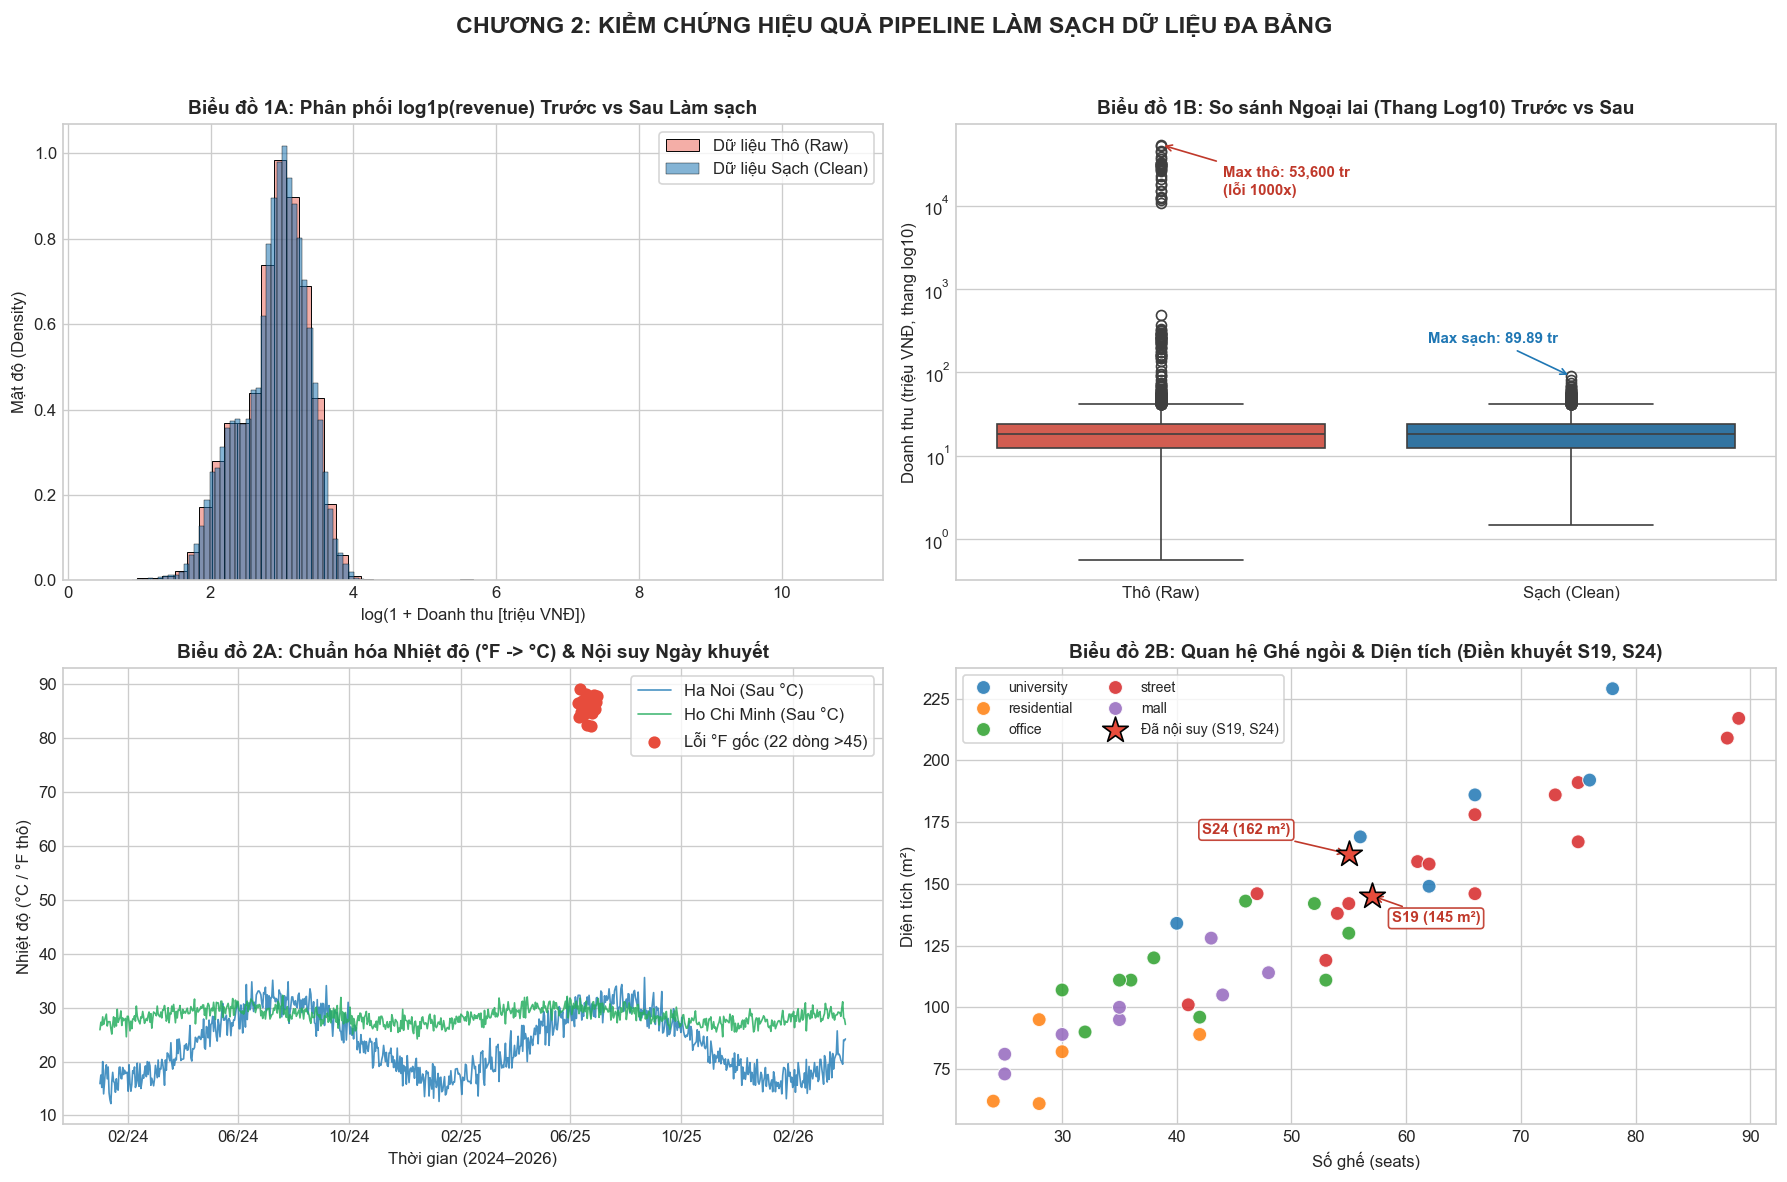

In [4]:
# CHART 1 & CHART 2: TRỰC QUAN HÓA HIỆU QUẢ LÀM SẠCH DỮ LIỆU
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1A: Phân phối log1p(revenue) Raw vs Clean
ax = axes[0, 0]
sns.histplot(np.log1p(train_raw["revenue"]), bins=60, color="#E74C3C", alpha=0.45, label="Dữ liệu Thô (Raw)", ax=ax, stat="density")
sns.histplot(np.log1p(train_c["revenue"]), bins=50, color="#1F77B4", alpha=0.55, label="Dữ liệu Sạch (Clean)", ax=ax, stat="density")
ax.set_title("Biểu đồ 1A: Phân phối log1p(revenue) Trước vs Sau Làm sạch", fontweight="bold")
ax.set_xlabel("log(1 + Doanh thu [triệu VNĐ])")
ax.set_ylabel("Mật độ (Density)")
ax.legend(frameon=True, facecolor="white")

# 1B: Boxplot ngoại lai (thang log10 để thấy rõ đuôi nhiễu 1000x & 0.1x)
ax = axes[0, 1]
bp_df = pd.DataFrame({
    "Doanh thu": pd.concat([train_raw["revenue"], train_c["revenue"]], ignore_index=True),
    "Trạng thái": ["Thô (Raw)"] * len(train_raw) + ["Sạch (Clean)"] * len(train_c),
})
sns.boxplot(data=bp_df, x="Trạng thái", y="Doanh thu", palette={"Thô (Raw)": "#E74C3C", "Sạch (Clean)": "#1F77B4"}, ax=ax)
ax.set_yscale("log")
ax.set_title("Biểu đồ 1B: So sánh Ngoại lai (Thang Log10) Trước vs Sau", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Doanh thu (triệu VNĐ, thang log10)")
ax.annotate(f"Max thô: {train_raw['revenue'].max():,.0f} tr\n(lỗi 1000x)", xy=(0, train_raw["revenue"].max()),
            xytext=(0.15, train_raw["revenue"].max() * 0.25),
            arrowprops=dict(arrowstyle="->", color="#C0392B"), fontsize=9, fontweight="bold", color="#C0392B")
ax.annotate(f"Max sạch: {train_c['revenue'].max():.2f} tr", xy=(1, train_c["revenue"].max()),
            xytext=(0.65, train_c["revenue"].max() * 2.5),
            arrowprops=dict(arrowstyle="->", color="#1F77B4"), fontsize=9, fontweight="bold", color="#1F77B4")

# 2A: Làm sạch nhiệt độ °F -> °C theo thời gian
ax = axes[1, 0]
w_raw_plot = weather_raw.copy()
w_raw_plot["date"] = pd.to_datetime(w_raw_plot["date"])
w_f_pts = w_raw_plot[w_raw_plot["temp_c"] > 45.0]
for c_name, col_hex in [("Ha Noi", "#2980B9"), ("Ho Chi Minh", "#27AE60")]:
    sub_c = weather_c[weather_c["city"] == c_name]
    ax.plot(sub_c["date"], sub_c["temp_c"], linewidth=1.0, alpha=0.85, color=col_hex, label=f"{c_name} (Sau °C)")
ax.scatter(w_f_pts["date"], w_f_pts["temp_c"], color="#E74C3C", s=40, zorder=5, label=f"Lỗi °F gốc ({len(w_f_pts)} dòng >45)")
ax.set_title("Biểu đồ 2A: Chuẩn hóa Nhiệt độ (°F -> °C) & Nội suy Ngày khuyết", fontweight="bold")
ax.set_xlabel("Thời gian (2024–2026)")
ax.set_ylabel("Nhiệt độ (°C / °F thô)")
ax.legend(frameon=True, facecolor="white", loc="upper right")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))

# 2B: Điền khuyết diện tích cửa hàng (area_m2 vs seats)
ax = axes[1, 1]
obs_stores = stores_c[~stores_c["store_id"].isin(raw_area_na)]
imp_stores = stores_c[stores_c["store_id"].isin(raw_area_na)]
sns.scatterplot(data=obs_stores, x="seats", y="area_m2", hue="store_type", s=70, alpha=0.85, ax=ax)
ax.scatter(imp_stores["seats"], imp_stores["area_m2"], color="#E74C3C", marker="*", s=260, edgecolor="black", zorder=6, label="Đã nội suy (S19, S24)")
for _, row in imp_stores.iterrows():
    is_s24 = row["store_id"] == "S24"
    xyoff = (-88, 12) if is_s24 else (12, -16)
    ax.annotate(
        f"{row['store_id']} ({row['area_m2']:.0f} m²)",
        (row["seats"], row["area_m2"]),
        xytext=xyoff,
        textcoords="offset points",
        fontweight="bold",
        color="#C0392B",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.22", facecolor="white", alpha=0.92, edgecolor="#C0392B"),
        arrowprops=dict(arrowstyle="->", color="#C0392B", lw=1.0),
    )
ax.set_title("Biểu đồ 2B: Quan hệ Ghế ngồi & Diện tích (Điền khuyết S19, S24)", fontweight="bold")
ax.set_xlabel("Số ghế (seats)")
ax.set_ylabel("Diện tích (m²)")
ax.legend(frameon=True, facecolor="white", fontsize=8.5, ncol=2)

fig.suptitle("CHƯƠNG 2: KIỂM CHỨNG HIỆU QUẢ PIPELINE LÀM SẠCH DỮ LIỆU ĐA BẢNG", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


---
# Chương 3: Khám phá Dữ liệu Chuyên sâu (EDA) & Quy luật Kinh doanh 2024–2026 (`Step 2b / P2`)

Việc kết hợp bảng lịch sử sạch `train_c` với `stores_c`, `weather_c` và lịch lễ/Tết cho phép vạch ra **6 quy luật vận hành cốt lõi** giải thích biến động doanh thu của toàn chuỗi:
1. **Phân hóa mạnh theo loại hình & thành phố:** Nhóm mặt phố (`street`) và trung tâm thương mại (`mall`) dẫn đầu doanh thu bình quân; trong khi `residential` thấp nhất. Cùng phân khúc nhưng tại TP.HCM và Hà Nội mang cấu trúc ngày thường – cuối tuần khác nhau (`office` Hà Nội sụt mạnh cuối tuần, `mall` tăng vọt T7–CN).
2. **Vòng đời khai trương cửa hàng mới (`days_since_open`):**
   - `0–2` ngày đầu (*Grand Opening*): Doanh thu tăng đột biến nhờ hiệu ứng khai trương & ưu đãi mở bán.
   - `3–62` ngày (*Ramp-up*): Tăng trưởng tuyến tính dần khi quán tích lũy tệp khách quen.
   - `>= 63` ngày (*Mature*): Ổn định theo mặt bằng dài hạn của điểm bán.
3. **Nhịp mùa vụ sinh viên (`university`):** Quán gần đại học sụt giảm rõ rệt vào **Tháng 7–8** (kỳ nghỉ hè) và phục hồi mạnh vào **Tháng 9** (nhập học).
4. **Hiệu ứng phi tuyến của Thời tiết:** Mưa nhẹ (`0–15 mm`) chỉ làm giảm nhẹ lượng khách vãng lai, nhưng mưa lớn (`> 15 mm`) đánh sập doanh thu nhóm `street` nhiều hơn hẳn nhóm `mall` (có mái che/gửi xe trong nhà).
5. **Đòn bẩy Khuyến mãi (`is_promo`):** Ngày chạy khuyến mãi kéo doanh thu bình quân toàn chuỗi tăng hơn **`+30%`**, mạnh nhất ở nhóm `mall` và `street`, đặc biệt khi kết hợp với cuối tuần.
6. **So sánh cùng kỳ Q1 (`2024 vs 2025 vs 2026`) & Sự dịch chuyển lịch Tết Âm lịch:**
   - **Tết 2024:** Mùng 1 rơi vào **10/02/2024**.
   - **Tết 2025:** Mùng 1 rơi sớm vào **29/01/2025**.
   - **Tết 2026:** Mùng 1 rơi muộn vào **17/02/2026** $\rightarrow$ kéo theo **Valentine `14/02/2026` rơi đúng vào `27 tháng Chạp`**. Không thể căn cứ theo ngày dương lịch cứng; bắt buộc phải căn trục tương đối **`tet_offset = date - tet_date`** chia **10 giai đoạn Tết**.


In [5]:
# Tổng hợp dữ liệu giàu ngữ cảnh phục vụ EDA (giữ nguyên toàn bộ lịch sử đã làm sạch)
eda_df = enrich_data(train_c, stores_c, weather_c, nat_hol, evt_hol, tet_dates)
eda_df["year"] = eda_df["date"].dt.year
eda_df["month"] = eda_df["date"].dt.month
eda_df["dow"] = eda_df["date"].dt.dayofweek
eda_df["days_open"] = (eda_df["date"] - eda_df["open_date"]).dt.days

# 1. Bảng phân bố & doanh thu lịch sử theo Thành phố x Loại hình
print("1. THỐNG KÊ MẠNG LƯỚI & DOANH THU LỊCH SỬ (2024–2025) THEO THÀNH PHỐ x LOẠI HÌNH:")
city_type_eda = (
    eda_df.groupby(["city", "store_type"])
    .agg(
        So_cua_hang=("store_id", "nunique"),
        So_quan_sat=("revenue", "count"),
        Mean_rev=("revenue", "mean"),
        Median_rev=("revenue", "median"),
        Promo_Mean=("revenue", lambda s: s[eda_df.loc[s.index, "is_promo"] == 1].mean()),
        NonPromo_Mean=("revenue", lambda s: s[eda_df.loc[s.index, "is_promo"] == 0].mean()),
    )
    .reset_index()
)
city_type_eda["Promo_Uplift_%"] = (city_type_eda["Promo_Mean"] / city_type_eda["NonPromo_Mean"] - 1.0) * 100
display(city_type_eda.round(2))

# 2. Tác động tổng thể của khuyến mãi & vòng đời khai trương
p0 = eda_df.loc[eda_df["is_promo"] == 0, "revenue"]
p1 = eda_df.loc[eda_df["is_promo"] == 1, "revenue"]
print(f"2. HIỆU ỨNG KHUYẾN MÃI LỊCH SỬ: Non-promo mean={p0.mean():.2f} (med={p0.median():.2f}) | "
      f"Promo mean={p1.mean():.2f} (med={p1.median():.2f}) => Tăng +{(p1.mean()/p0.mean()-1)*100:.1f}% mean / +{(p1.median()/p0.median()-1)*100:.1f}% median")

# 3. Bảng so sánh cùng kỳ Quý 1: Q1/2024 vs Q1/2025 vs Q1/2026
yoy_rows = []
for yr, df_src, is_test in [
    (2024, train_c[(train_c["date"] >= "2024-01-01") & (train_c["date"] <= "2024-03-31")], False),
    (2025, train_c[(train_c["date"] >= "2025-01-01") & (train_c["date"] <= "2025-03-31")], False),
    (2026, test_c, True),
]:
    n_rows = len(df_src)
    n_stores = df_src["store_id"].nunique()
    n_promo = int(df_src["is_promo"].sum())
    tet_dt = tet_dates[yr].strftime("%d/%m/%Y")
    val_offset = int((pd.Timestamp(f"{yr}-02-14") - tet_dates[yr]).days)
    yoy_rows.append({
        "Kỳ": f"Q1/{yr}" + (" (Test)" if is_test else " (Train)"),
        "Số dòng": f"{n_rows:,}",
        "Số cửa hàng": n_stores,
        "Ngày Promo (%)": f"{n_promo} ({n_promo/n_rows*100:.2f}%)",
        "Mùng 1 Tết": tet_dt,
        "14/02 cách Tết": f"{val_offset:+d} ngày",
        "Median (tr VNĐ)": f"{df_src['revenue'].median():.2f}" if not is_test else "Cần dự báo",
        "Mean (tr VNĐ)": f"{df_src['revenue'].mean():.2f}" if not is_test else "Cần dự báo",
    })

print("\n3. BẢNG SO SÁNH CÙNG KỲ QUÝ 1 (YoY Q1/2024 vs Q1/2025 vs Q1/2026):")
display(pd.DataFrame(yoy_rows))


1. THỐNG KÊ MẠNG LƯỚI & DOANH THU LỊCH SỬ (2024–2025) THEO THÀNH PHỐ x LOẠI HÌNH:


,city,store_type,So_cua_hang,So_quan_sat,Mean_rev,Median_rev,Promo_Mean,NonPromo_Mean,Promo_Uplift_%
0,Ha Noi,mall,4,2470,19.54,18.23,24.54,18.86,30.15
1,Ha Noi,office,5,3028,18.84,18.31,23.96,18.17,31.88
2,Ha Noi,residential,3,2023,7.34,7.17,9.37,7.07,32.57
3,Ha Noi,street,9,5354,22.89,21.84,29.26,22.10,32.44
4,Ha Noi,university,3,860,13.57,12.99,17.38,13.08,32.84
5,Ho Chi Minh,mall,4,1275,26.16,24.23,31.95,25.45,25.55
6,Ho Chi Minh,office,6,4241,16.71,16.01,21.44,16.08,33.30
7,Ho Chi Minh,residential,2,1430,13.20,12.26,16.44,12.77,28.78
8,Ho Chi Minh,street,6,3697,24.06,23.56,30.78,23.22,32.53
9,Ho Chi Minh,university,3,2122,16.24,15.24,20.91,15.62,33.83


2. HIỆU ỨNG KHUYẾN MÃI LỊCH SỬ: Non-promo mean=18.25 (med=17.84) | Promo mean=23.92 (med=23.45) => Tăng +31.0% mean / +31.4% median

3. BẢNG SO SÁNH CÙNG KỲ QUÝ 1 (YoY Q1/2024 vs Q1/2025 vs Q1/2026):


,Kỳ,Số dòng,Số cửa hàng,Ngày Promo (%),Mùng 1 Tết,14/02 cách Tết,Median (tr VNĐ),Mean (tr VNĐ)
0,Q1/2024 (Train),"2,962",34,325 (10.97%),10/02/2024,+4 ngày,17.12,17.48
1,Q1/2025 (Train),"3,170",38,365 (11.51%),29/01/2025,+16 ngày,18.57,18.94
2,Q1/2026 (Test),"3,869",44,380 (9.82%),17/02/2026,-3 ngày,Cần dự báo,Cần dự báo


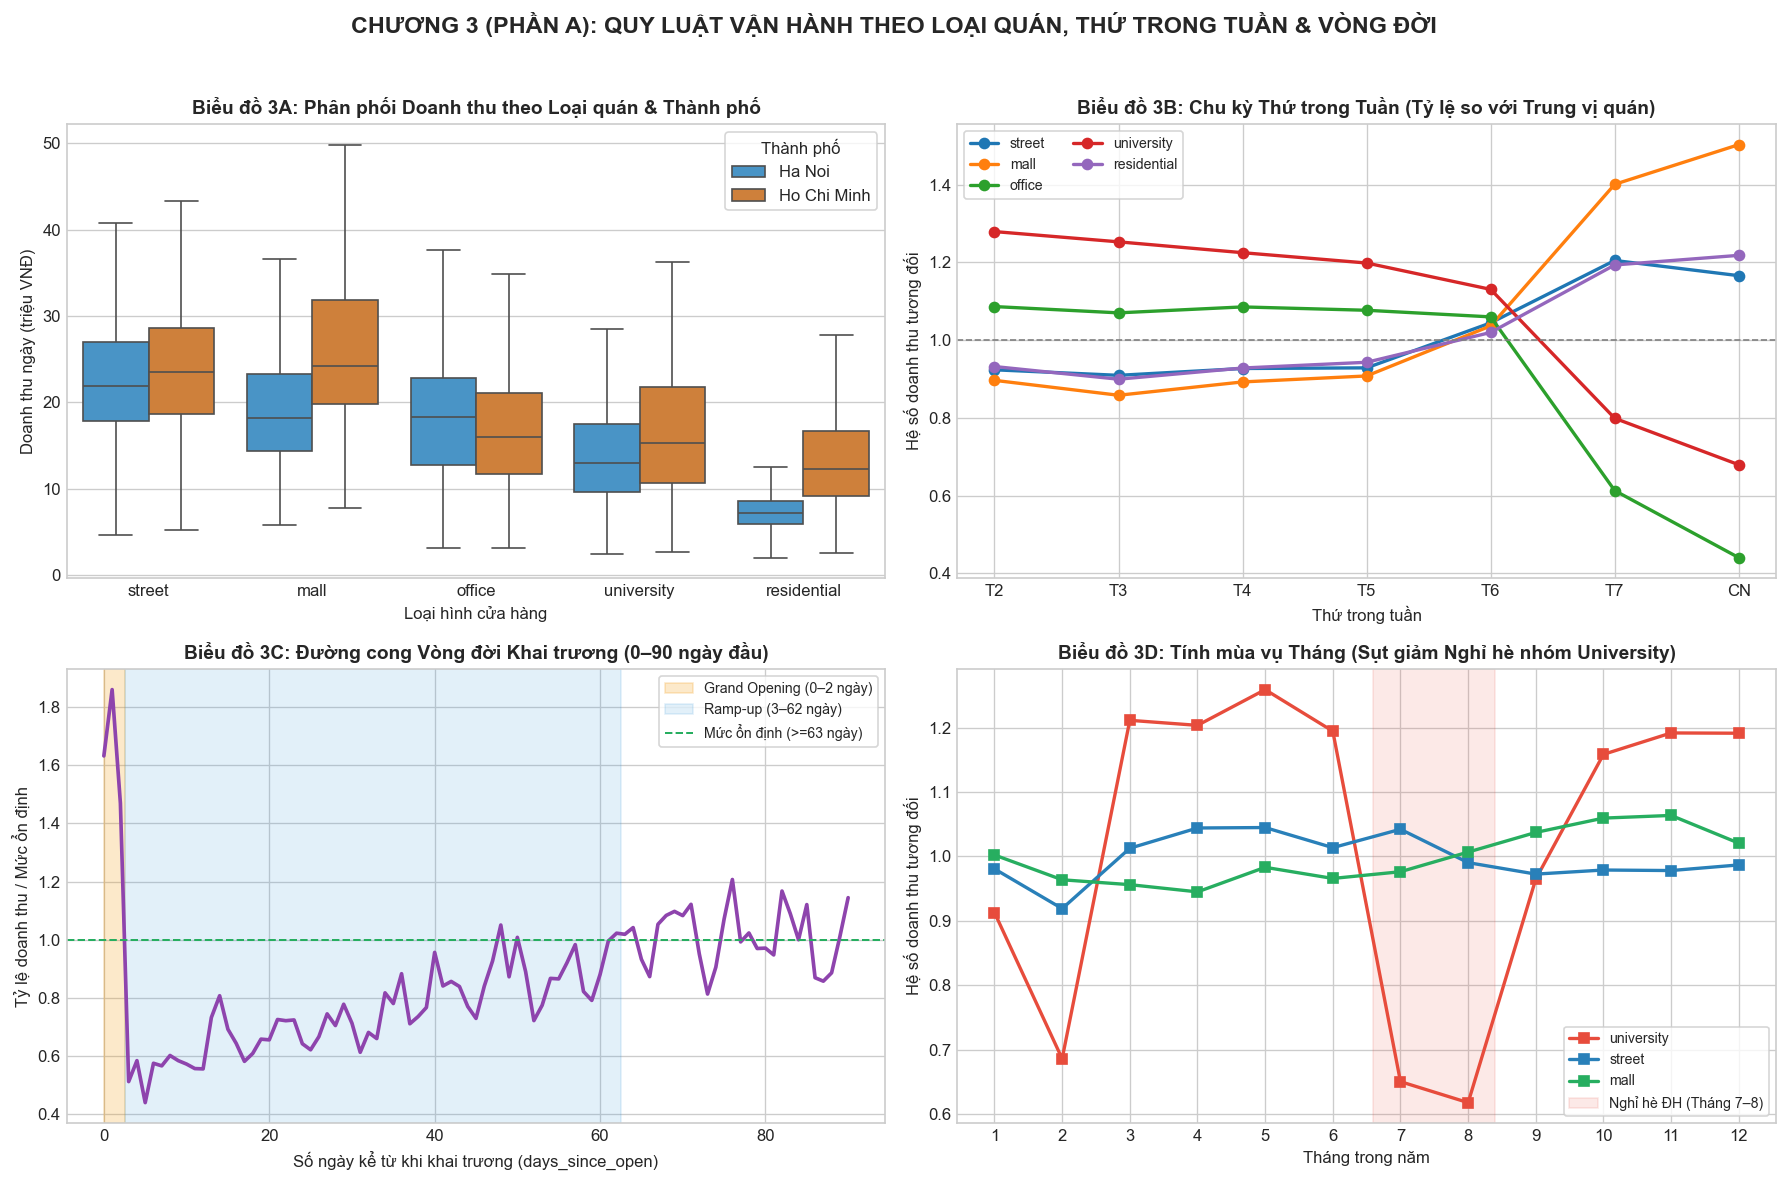

In [6]:
# CHART 3: HỆ SINH THÁI CỬA HÀNG, CHU KỲ THỨ TRONG TUẦN, VÒNG ĐỜI & MÙA HÈ ĐẠI HỌC
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
type_order = ["street", "mall", "office", "university", "residential"]
dow_labels = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

# 3A: Boxplot theo loại hình x thành phố
ax = axes[0, 0]
sns.boxplot(data=eda_df, x="store_type", y="revenue", hue="city", order=type_order,
            palette={"Ha Noi": "#3498DB", "Ho Chi Minh": "#E67E22"}, showfliers=False, ax=ax)
ax.set_title("Biểu đồ 3A: Phân phối Doanh thu theo Loại quán & Thành phố", fontweight="bold")
ax.set_xlabel("Loại hình cửa hàng")
ax.set_ylabel("Doanh thu ngày (triệu VNĐ)")
ax.legend(title="Thành phố", frameon=True, facecolor="white")

# 3B: Hệ số mùa vụ theo thứ trong tuần (chuẩn hóa về trung vị từng quán)
ax = axes[0, 1]
store_med = eda_df.groupby("store_id")["revenue"].transform("median")
eda_df["rel_rev"] = eda_df["revenue"] / store_med
dow_profile = eda_df.groupby(["store_type", "dow"])["rel_rev"].median().reset_index()
for st in type_order:
    sub = dow_profile[dow_profile["store_type"] == st]
    ax.plot(sub["dow"], sub["rel_rev"], marker="o", linewidth=2, label=st)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(7))
ax.set_xticklabels(dow_labels)
ax.set_title("Biểu đồ 3B: Chu kỳ Thứ trong Tuần (Tỷ lệ so với Trung vị quán)", fontweight="bold")
ax.set_xlabel("Thứ trong tuần")
ax.set_ylabel("Hệ số doanh thu tương đối")
ax.legend(frameon=True, facecolor="white", ncol=2, fontsize=8.5)

# 3C: Vòng đời quán mới mở (days_open từ 0 đến 90 ngày)
ax = axes[1, 0]
lc_df = eda_df[(eda_df["days_open"] >= 0) & (eda_df["days_open"] <= 90)].copy()
mature_med = eda_df[eda_df["days_open"] >= 63].groupby("store_id")["revenue"].median()
lc_df["mature_med"] = lc_df["store_id"].map(mature_med)
lc_valid = lc_df.dropna(subset=["mature_med"]).copy()
lc_valid["lc_ratio"] = lc_valid["revenue"] / lc_valid["mature_med"]
lc_curve = lc_valid.groupby("days_open")["lc_ratio"].median().reset_index()
ax.plot(lc_curve["days_open"], lc_curve["lc_ratio"], color="#8E44AD", linewidth=2.2)
ax.axvspan(0, 2.5, color="#F39C12", alpha=0.22, label="Grand Opening (0–2 ngày)")
ax.axvspan(2.5, 62.5, color="#3498DB", alpha=0.14, label="Ramp-up (3–62 ngày)")
ax.axhline(1.0, color="#27AE60", linestyle="--", linewidth=1.2, label="Mức ổn định (>=63 ngày)")
ax.set_title("Biểu đồ 3C: Đường cong Vòng đời Khai trương (0–90 ngày đầu)", fontweight="bold")
ax.set_xlabel("Số ngày kể từ khi khai trương (days_since_open)")
ax.set_ylabel("Tỷ lệ doanh thu / Mức ổn định")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

# 3D: Nhịp mùa vụ 12 tháng: University vs Street
ax = axes[1, 1]
monthly_rel = (
    eda_df[eda_df["store_type"].isin(["university", "street", "mall"])]
    .groupby(["store_type", "month"])["rel_rev"]
    .median()
    .reset_index()
)
for st, col in [("university", "#E74C3C"), ("street", "#2980B9"), ("mall", "#27AE60")]:
    sub = monthly_rel[monthly_rel["store_type"] == st]
    ax.plot(sub["month"], sub["rel_rev"], marker="s", linewidth=2, color=col, label=st)
ax.axvspan(6.6, 8.4, color="#E74C3C", alpha=0.12, label="Nghỉ hè ĐH (Tháng 7–8)")
ax.set_xticks(range(1, 13))
ax.set_title("Biểu đồ 3D: Tính mùa vụ Tháng (Sụt giảm Nghỉ hè nhóm University)", fontweight="bold")
ax.set_xlabel("Tháng trong năm")
ax.set_ylabel("Hệ số doanh thu tương đối")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

fig.suptitle("CHƯƠNG 3 (PHẦN A): QUY LUẬT VẬN HÀNH THEO LOẠI QUÁN, THỨ TRONG TUẦN & VÒNG ĐỜI", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


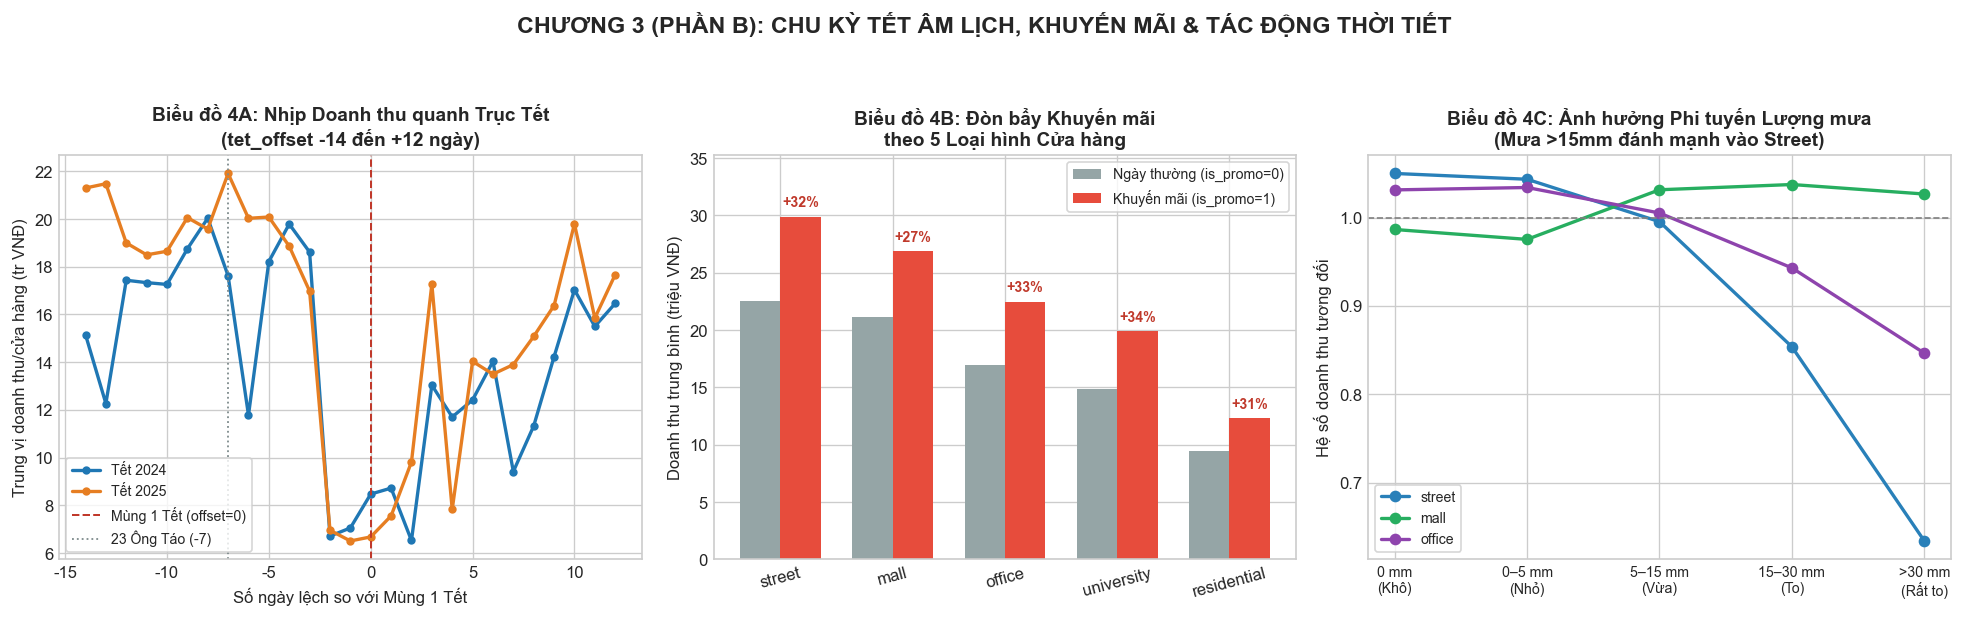

In [7]:
# CHART 4: ĐỘNG LỰC NGOẠI SINH (CHU KỲ TẾT 10 GIAI ĐOẠN, KHUYẾN MÃI & MƯA PHI TUYẾN)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.2))

# 4A: Doanh thu quanh trục Tết (tet_offset -14..+12) năm 2024 & 2025
ax = axes[0]
tet_win = eda_df[eda_df["tet_offset"].between(-14, 12)]
for yr, col in [(2024, "#1F77B4"), (2025, "#E67E22")]:
    sub = tet_win[tet_win["year"] == yr].groupby("tet_offset")["revenue"].median()
    ax.plot(sub.index, sub.values, marker="o", markersize=4, linewidth=2, color=col, label=f"Tết {yr}")
ax.axvline(0, color="#C0392B", linestyle="--", linewidth=1.2, label="Mùng 1 Tết (offset=0)")
ax.axvline(-7, color="#7F8C8D", linestyle=":", linewidth=1.1, label="23 Ông Táo (-7)")
ax.set_title("Biểu đồ 4A: Nhịp Doanh thu quanh Trục Tết\n(tet_offset -14 đến +12 ngày)", fontweight="bold")
ax.set_xlabel("Số ngày lệch so với Mùng 1 Tết")
ax.set_ylabel("Trung vị doanh thu/cửa hàng (tr VNĐ)")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

# 4B: Sức bật Khuyến mãi theo Loại quán (Barplot + % uplift)
ax = axes[1]
promo_tbl = eda_df.groupby(["store_type", "is_promo"])["revenue"].mean().unstack()
promo_tbl = promo_tbl.loc[type_order]
x_idx = np.arange(len(type_order))
w = 0.36
b0 = ax.bar(x_idx - w/2, promo_tbl[0], width=w, color="#95A5A6", label="Ngày thường (is_promo=0)")
b1 = ax.bar(x_idx + w/2, promo_tbl[1], width=w, color="#E74C3C", label="Khuyến mãi (is_promo=1)")
for i, st in enumerate(type_order):
    up = (promo_tbl.loc[st, 1] / promo_tbl.loc[st, 0] - 1) * 100
    ax.text(i + w/2, promo_tbl.loc[st, 1] + 0.6, f"+{up:.0f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#C0392B")
ax.set_xticks(x_idx)
ax.set_xticklabels(type_order, rotation=15)
ax.set_ylim(0, promo_tbl.values.max() * 1.18)
ax.set_title("Biểu đồ 4B: Đòn bẩy Khuyến mãi\ntheo 5 Loại hình Cửa hàng", fontweight="bold")
ax.set_ylabel("Doanh thu trung bình (triệu VNĐ)")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

# 4C: Tác động phi tuyến của lượng mưa theo nhóm Street / Mall / Office
ax = axes[2]
eda_df["rain_bin"] = pd.cut(
    eda_df["rain_mm"],
    bins=[-0.1, 0.01, 5.0, 15.0, 30.0, 500.0],
    labels=["0 mm\n(Khô)", "0–5 mm\n(Mưa nhỏ)", "5–15 mm\n(Vừa)", "15–30 mm\n(To)", ">30 mm\n(Rất to)"],
)
for st, col in [("street", "#2980B9"), ("mall", "#27AE60"), ("office", "#8E44AD")]:
    sub = eda_df[eda_df["store_type"] == st].groupby("rain_bin", observed=False)["rel_rev"].median()
    ax.plot(range(len(sub)), sub.values, marker="o", linewidth=2, color=col, label=st)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(5))
ax.set_xticklabels(["0 mm\n(Khô)", "0–5 mm\n(Nhỏ)", "5–15 mm\n(Vừa)", "15–30 mm\n(To)", ">30 mm\n(Rất to)"], fontsize=8.5)
ax.set_title("Biểu đồ 4C: Ảnh hưởng Phi tuyến Lượng mưa\n(Mưa >15mm đánh mạnh vào Street)", fontweight="bold")
ax.set_ylabel("Hệ số doanh thu tương đối")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

fig.suptitle("CHƯƠNG 3 (PHẦN B): CHU KỲ TẾT ÂM LỊCH, KHUYẾN MÃI & TÁC ĐỘNG THỜI TIẾT", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


---
# Chương 4: Chiến lược Chia tập Chống Rò rỉ & Kỹ thuật Đặc trưng (`Step 4 + Step 5 / P3`)

### 4.1. Chiến lược Chia tập Time-Based Split (Chống Data Leakage)
Trong bài toán chuỗi thời gian, dùng *Random K-Fold* sẽ để dữ liệu ngày tương lai lọt vào tập huấn luyện cho ngày quá khứ (**Data Leakage**), tạo điểm đánh giá ảo trên máy nhưng sụp đổ khi dự báo Q1/2026. Tuân thủ **Rule 1 & Rule 2 (Chapter 4)**:
- Giữ kín `test.csv` (Q1/2026) đến tận bước triển khai cuối cùng.
- Thiết kế **4 cửa sổ mở rộng theo thời gian (*Out-of-Time Expanding Window CV*)** phủ trọn **4 Quý năm 2025**: mọi thống kê làm sạch tỷ lệ `ratio`, Bayesian Prior, trọng số Ridge và trạng thái `u_T_` chỉ được phép tính từ dữ liệu `< val_start`.

### 4.2. Ma trận Đặc trưng Hai tầng (Linear Stage-1 + Nonlinear Stage-2 GBDT)
Cả `src/features.py` (dành cho kiểm chứng & mô hình chuẩn) và `src/cafe_model_v3.py` (mô hình tối ưu) đều mã hóa đầy đủ cấu trúc nghiệp vụ phát hiện từ EDA:
- **Tương tác loại quán $\times$ lịch:** `st_dow` (`35` cặp), `st_is_nat`, `st_is_evt`, `st_tet` (tách **10 giai đoạn Tết** từ `-14` đến `+12` ngày theo `tet_offset` quanh Mùng 1).
- **Vòng đời & mùa vụ đặc thù:** `grand_open` (`0–2` ngày), `ramp_deficit` (`3–62` ngày giảm tuyến tính về 0), `uni_summer` (Tháng 7–8), `uni_september` (Tháng 9), `global_trend`.
- **Khuyến mãi & ngày lễ 2026:** `is_promo_global`, `promo_weekend`, `promo_{store_type}`, `is_valentine`, `is_womens_day`, `is_new_year`.
- **Thời tiết phi tuyến & dị thường nhiệt độ vùng:** `rain_light_{store_type}` (`0–15mm` chuẩn hóa), `rain_heavy_{store_type}` (`>15mm`), và nhiệt độ lệch chuẩn theo từng thành phố (`Ha Noi` nền `24°C`, `Ho Chi Minh` nền `28°C`).


,Fold Kiểm định,Khoảng Train (< val_start),Số dòng Train,Khoảng Validation,Số dòng Val
0,Q1/2025,2024-01-01 -> 2024-12-31,"12,281",2025-01-01 -> 2025-03-31,"3,170"
1,Q2/2025,2024-01-01 -> 2025-03-31,"15,451",2025-04-01 -> 2025-06-30,"3,531"
2,Q3/2025,2024-01-01 -> 2025-06-30,"18,982",2025-07-01 -> 2025-09-30,"3,686"
3,Q4/2025,2024-01-01 -> 2025-09-30,"22,668",2025-10-01 -> 2025-12-31,"3,832"
4,Production Q1/2026,2024-01-01 -> 2025-12-31 (100%),"26,500",2026-01-01 -> 2026-03-31,"3,869"



Số đặc trưng trong src.features.build_shared_matrix : 131 cột
Số đặc trưng Stage 1 (Ridge) trong CafeRevenueModelV3 : 146 cột + 45 store_id
Số đặc trưng Stage 2 (HistGBDT) trong CafeRevenueModelV3: 31 cột


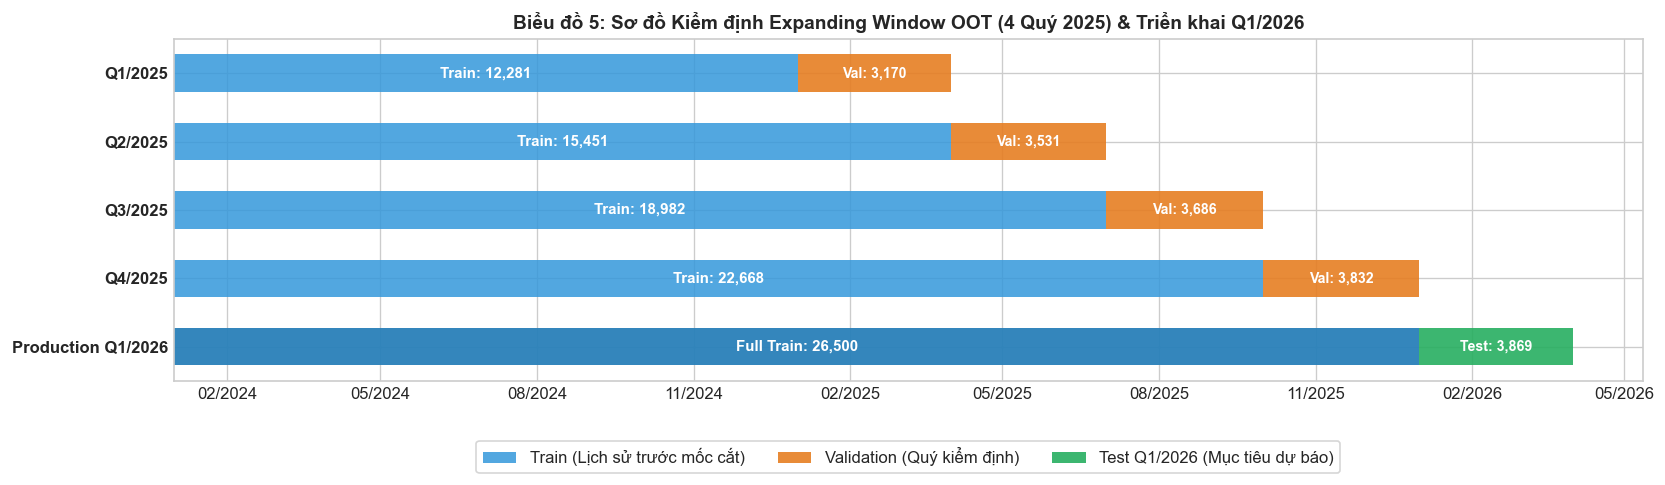

In [8]:
# Trực quan hóa 4 mốc chia Out-of-Time 2025 + Ma trận đặc trưng từ src/features.py & CafeRevenueModelV3
split_rows = []
for q_name, (s, e) in EVAL_QUARTERS.items():
    tr_n = int((train_c["date"] < s).sum())
    va_n = int(((train_c["date"] >= s) & (train_c["date"] <= e)).sum())
    split_rows.append({
        "Fold Kiểm định": q_name,
        "Khoảng Train (< val_start)": f"2024-01-01 -> {(pd.Timestamp(s) - pd.Timedelta(days=1)).strftime('%Y-%m-%d')}",
        "Số dòng Train": f"{tr_n:,}",
        "Khoảng Validation": f"{s} -> {e}",
        "Số dòng Val": f"{va_n:,}",
    })
split_rows.append({
    "Fold Kiểm định": "Production Q1/2026",
    "Khoảng Train (< val_start)": "2024-01-01 -> 2025-12-31 (100%)",
    "Số dòng Train": f"{len(train_c):,}",
    "Khoảng Validation": f"{test_c['date'].min().strftime('%Y-%m-%d')} -> {test_c['date'].max().strftime('%Y-%m-%d')}",
    "Số dòng Val": f"{len(test_c):,}",
})
display(pd.DataFrame(split_rows))

# Kiểm tra kích thước ma trận đặc trưng từ src.features & CafeRevenueModelV3
X_shared_demo = build_shared_matrix(eda_df)
m_demo = CafeRevenueModelV3().fit(train_raw, stores_raw, weather_raw, holidays_raw)
print(f"\nSố đặc trưng trong src.features.build_shared_matrix : {X_shared_demo.shape[1]} cột")
print(f"Số đặc trưng Stage 1 (Ridge) trong CafeRevenueModelV3 : {len(m_demo.shared_cols_)} cột + {len(m_demo.store_cols_)} store_id")
print(f"Số đặc trưng Stage 2 (HistGBDT) trong CafeRevenueModelV3: {len(m_demo.gbdt_cols_)} cột")

# CHART 5: SƠ ĐỒ EXPANDING WINDOW OUT-OF-TIME SPLIT
fig, ax = plt.subplots(figsize=(14, 4.2))
y_positions = np.arange(len(split_rows))[::-1]
t0 = pd.Timestamp("2024-01-01")

for idx, (q_name, (s, e)) in enumerate(EVAL_QUARTERS.items()):
    y_pos = y_positions[idx]
    s_dt, e_dt = pd.Timestamp(s), pd.Timestamp(e)
    tr_n = int((train_c["date"] < s).sum())
    va_n = int(((train_c["date"] >= s) & (train_c["date"] <= e)).sum())
    ax.barh(y_pos, (s_dt - t0).days, left=mdates.date2num(t0), height=0.55, color="#3498DB", alpha=0.85,
            label="Train (Lịch sử trước mốc cắt)" if idx == 0 else "")
    ax.barh(y_pos, (e_dt - s_dt).days + 1, left=mdates.date2num(s_dt), height=0.55, color="#E67E22", alpha=0.9,
            label="Validation (Quý kiểm định)" if idx == 0 else "")
    ax.text(mdates.date2num(t0) + (s_dt - t0).days / 2, y_pos, f"Train: {tr_n:,}", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
    ax.text(mdates.date2num(s_dt) + ((e_dt - s_dt).days + 1) / 2, y_pos, f"Val: {va_n:,}", va="center", ha="center", color="white", fontweight="bold", fontsize=8.5)

# Dòng Production 2026
y_prod = y_positions[-1]
s26, e26 = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-03-31")
ax.barh(y_prod, (s26 - t0).days, left=mdates.date2num(t0), height=0.55, color="#2980B9", alpha=0.95)
ax.barh(y_prod, (e26 - s26).days + 1, left=mdates.date2num(s26), height=0.55, color="#27AE60", alpha=0.9,
        label="Test Q1/2026 (Mục tiêu dự báo)")
ax.text(mdates.date2num(t0) + (s26 - t0).days / 2, y_prod, f"Full Train: {len(train_c):,}", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
ax.text(mdates.date2num(s26) + ((e26 - s26).days + 1) / 2, y_prod, f"Test: {len(test_c):,}", va="center", ha="center", color="white", fontweight="bold", fontsize=8.5)

ax.set_yticks(y_positions)
ax.set_yticklabels([r["Fold Kiểm định"] for r in split_rows], fontweight="bold")
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("Biểu đồ 5: Sơ đồ Kiểm định Expanding Window OOT (4 Quý 2025) & Triển khai Q1/2026", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


---
# Chương 5: Kiến trúc `CafeRevenueModelV3`, Đấu trường Mô hình & Kiểm định Overfitting (`Step 6 + Step 7a / P4`)

### 5.1. Tại sao các mô hình chuẩn đơn lẻ chưa đạt ngưỡng tối ưu?
Một mình Hồi quy tuyến tính (`Ridge`) bỏ sót tương tác phi tuyến phức tạp (ví dụ mưa lớn + khuyến mãi + thứ 7 tại từng quán); ngược lại một mình Cây quyết định (`Random Forest` / `HistGBDT`) lại ngoại suy kém xu hướng dài hạn `global_trend`, ngày Tết 10 pha ít mẫu, và dễ dao động mạnh ở các quán mới mở ít dữ liệu.

### 5.2. Kiến trúc Phân tầng 5 lớp của `CafeRevenueModelV3`
Mô hình tối ưu kết hợp điểm mạnh của hồi quy có cấu trúc, thống kê Bayes và Boosting phần dư:
1. **Stage 1 — Weighted Ridge trên $\log(y)$ (`alpha=0.40`):** Ước lượng đồng thời `store_id` và `146` đặc trưng chung với trọng số $w = 1.0$ cho ngày có thời tiết khớp trực tiếp (`w = 0.15` cho ngày nội suy) nhằm giảm ảnh hưởng của điểm thời tiết ước lượng.
2. **Dual-Window Exponential Weighting + Lọc sốc chéo:** Tính thặng dư riêng từng quán bằng trung bình trọng số hàm mũ hai cửa sổ (*Half-life* dài `365` ngày giữ nền cơ sở với trọng số `0.25`, *Half-life* trung bình `50` ngày bám sát phong độ gần nhất với trọng số `0.75`), đồng thời trừ `85%` cú sốc chung toàn thành phố (`cd_shock`) vào ngày thiếu thời tiết.
3. **Empirical Bayes / James-Stein Shrinkage về Store Metadata Prior:** Huấn luyện thêm một Ridge phụ từ đặc tính vật lý cửa hàng (`city`, `store_type`, `log_seats`, `log_area`, `has_parking`), rồi co cụm ước lượng mức nền từng quán:
   $$\hat{\alpha}_s = \frac{n_s}{n_s + k_{\text{meta}}} \bar{r}_s + \frac{k_{\text{meta}}}{n_s + k_{\text{meta}}} \hat{\alpha}^{\text{meta}}_s \quad (k_{\text{meta}} = 2.0)$$
   Nhờ đó, ngay cả quán mới khai trương ít dữ liệu cũng có điểm neo chắc chắn thay vì bị *overfit* vài ngày đầu.
4. **Kalman AR(1) State Propagation (`rho=0.80, scale=0.65`):** Nắm bắt quán tính phong độ `21` ngày sát điểm chốt train để truyền suy giảm dần sang đầu quý dự báo.
5. **Stage 2 — Constrained `HistGradientBoostingRegressor` + Taylor RMSLE Correction:** Học thặng dư phi tuyến (`max_depth=3, min_samples_leaf=45, l2=20.0`, trọng số `gbdt_weight=0.08`), sau đó hiệu chỉnh phân phối theo khai triển **Taylor bậc 2** trên $\log(1 + e^{\mu})$ với phương sai nhiễu $\sigma = 0.104$:
   $$u^* = \log(1 + e^{\mu}) + \frac{1}{2}\sigma^2 \frac{e^{\mu}}{(1 + e^{\mu})^2}, \quad \hat{y} = e^{u^*} - 1$$


In [9]:
# ĐẤU TRƯỜNG MÔ HÌNH QUA 4 QUÝ OUT-OF-TIME NĂM 2025 & KIỂM ĐỊNH OVERFITTING
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

def build_zoo_matrix(df_enriched, stores_df, cols_ref=None):
    X_sh = build_shared_matrix(df_enriched)
    X_sid = pd.get_dummies(df_enriched["store_id"], prefix="sid", dtype=float)
    X_city = pd.get_dummies(df_enriched["city"], prefix="city", dtype=float)
    X_meta = pd.DataFrame({
        "log_seats": np.log(df_enriched["seats"].values),
        "log_area": np.log(df_enriched["area_m2"].values),
        "has_parking": df_enriched["has_parking"].astype(float).values,
        "temp_c": df_enriched["temp_c"].values,
        "rain_mm": df_enriched["rain_mm"].values,
    }, index=df_enriched.index)
    X = pd.concat([X_sh, X_sid, X_city, X_meta], axis=1)
    if cols_ref is not None:
        X = X.reindex(columns=cols_ref, fill_value=0.0)
    return X

arena_rows = []
oof_records = []  # Lưu dự báo OOT 4 quý 2025 để vẽ Actual vs Predicted & Residuals ở Chương 6

for q_name, (val_start, val_end) in EVAL_QUARTERS.items():
    # Chú ý: tách train_raw TRƯỚC mốc val_start và clean độc lập trên phân đoạn train (tránh leakage!)
    tr_raw = train_raw[train_raw["date"] < val_start].copy()
    va_clean = train_c[(train_c["date"] >= val_start) & (train_c["date"] <= val_end)].copy()

    # Dọn dữ liệu phía Train chuẩn hóa riêng
    w_q = clean_weather(weather_raw, stores_c["city"].unique())
    n_h, e_h, t_d = clean_holidays(holidays_raw)
    tr_clean, _ = clean_train(tr_raw, stores_c)

    tr_enr = enrich_data(tr_clean, stores_c, w_q, n_h, e_h, t_d)
    va_enr = enrich_data(va_clean, stores_c, w_q, n_h, e_h, t_d)

    X_tr = build_zoo_matrix(tr_enr, stores_c)
    X_va = build_zoo_matrix(va_enr, stores_c, cols_ref=X_tr.columns)
    y_tr_log = np.log1p(tr_clean["revenue"].values)
    y_va_true = va_clean["revenue"].values

    # 1. BaselineWeekdayModel
    m_base = BaselineWeekdayModel().fit(tr_raw)
    base_tr = rmsle(tr_clean["revenue"].values, m_base.predict(tr_clean))
    base_va = rmsle(y_va_true, m_base.predict(va_clean))

    # 2. LinearRegression (clip log để minh họa rủi ro đa cộng tuyến khi không có L2)
    m_ols = LinearRegression().fit(X_tr, y_tr_log)
    p_ols = np.expm1(np.clip(m_ols.predict(X_va), 0.0, 7.0))
    ols_va = rmsle(y_va_true, p_ols)

    # 3. Ridge Regression
    m_ridge = Ridge(alpha=5.0).fit(X_tr, y_tr_log)
    ridge_va = rmsle(y_va_true, np.expm1(np.clip(m_ridge.predict(X_va), 0.0, 7.0)))

    # 4. DecisionTreeRegressor
    m_dt = DecisionTreeRegressor(max_depth=12, min_samples_leaf=15, random_state=42).fit(X_tr, y_tr_log)
    dt_va = rmsle(y_va_true, np.expm1(m_dt.predict(X_va)))

    # 5. RandomForestRegressor
    m_rf = RandomForestRegressor(n_estimators=40, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42).fit(X_tr, y_tr_log)
    rf_va = rmsle(y_va_true, np.expm1(m_rf.predict(X_va)))

    # 6. HistGradientBoostingRegressor (đơn lẻ)
    m_hgb = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.05, max_depth=5, min_samples_leaf=20, l2_regularization=5.0, random_state=42).fit(X_tr, y_tr_log)
    hgb_tr = rmsle(tr_clean["revenue"].values, np.expm1(m_hgb.predict(X_tr)))
    hgb_va = rmsle(y_va_true, np.expm1(m_hgb.predict(X_va)))

    # 7. CafeRevenueModelV3 (Kiến trúc Production)
    m_v3 = CafeRevenueModelV3().fit(tr_raw, stores_raw, weather_raw, holidays_raw)
    p_v3_tr = m_v3.predict(tr_clean)
    p_v3_va = m_v3.predict(va_clean)
    v3_tr = rmsle(tr_clean["revenue"].values, p_v3_tr)
    v3_va = rmsle(y_va_true, p_v3_va)

    arena_rows.append({
        "Quý": q_name,
        "Baseline_Val": base_va,
        "OLS_Val": ols_va,
        "Ridge_Val": ridge_va,
        "DecisionTree_Val": dt_va,
        "RandomForest_Val": rf_va,
        "HistGBDT_Val": hgb_va,
        "CafeV3_Val": v3_va,
        "Baseline_Train": base_tr,
        "HistGBDT_Train": hgb_tr,
        "CafeV3_Train": v3_tr,
        "Gap_V3": v3_va - v3_tr,
        "CaiThien_vs_Base_%": (base_va - v3_va) / base_va * 100,
    })

    va_oof = va_clean.copy().merge(stores_c[["store_id", "city", "store_type"]], on="store_id", how="left")
    va_oof["quarter"] = q_name
    va_oof["pred_v3"] = p_v3_va
    va_oof["pred_base"] = m_base.predict(va_clean)
    oof_records.append(va_oof)

arena_df = pd.DataFrame(arena_rows)
oof_df = pd.concat(oof_records, ignore_index=True)

# Tính trung bình 4 quý
avg_row = {"Quý": "TRUNG BÌNH 4 QUÝ"}
for col in arena_df.columns:
    if col != "Quý":
        avg_row[col] = arena_df[col].mean()
arena_summary = pd.concat([arena_df, pd.DataFrame([avg_row])], ignore_index=True)

print("1. BẢNG ĐẤU TRƯỜNG 7 MÔ HÌNH — VALIDATION RMSLE QUA 4 QUÝ 2025 (Càng thấp càng tốt):")
val_cols = ["Quý", "Baseline_Val", "OLS_Val", "DecisionTree_Val", "RandomForest_Val", "HistGBDT_Val", "Ridge_Val", "CafeV3_Val", "CaiThien_vs_Base_%"]
display(arena_summary[val_cols].round(4))

print("\n2. KIỂM ĐỊNH OVERFITTING — SO SÁNH TRAIN RMSLE vs VALIDATION RMSLE:")
ovf_cols = ["Quý", "Baseline_Train", "Baseline_Val", "HistGBDT_Train", "HistGBDT_Val", "CafeV3_Train", "CafeV3_Val", "Gap_V3"]
display(arena_summary[ovf_cols].round(4))


1. BẢNG ĐẤU TRƯỜNG 7 MÔ HÌNH — VALIDATION RMSLE QUA 4 QUÝ 2025 (Càng thấp càng tốt):


,Quý,Baseline_Val,OLS_Val,DecisionTree_Val,RandomForest_Val,HistGBDT_Val,Ridge_Val,CafeV3_Val,CaiThien_vs_Base_%
0,Q1/2025,0.2758,0.1107,0.2192,0.2065,0.2161,0.1151,0.1045,62.1209
1,Q2/2025,0.2391,0.1049,0.1933,0.1773,0.1689,0.1070,0.1027,57.0419
2,Q3/2025,0.2750,0.1121,0.2091,0.1896,0.1622,0.1128,0.1077,60.8416
3,Q4/2025,0.2275,0.1134,0.1873,0.1667,0.1571,0.1142,0.1123,50.6393
4,TRUNG BÌNH 4 QUÝ,0.2544,0.1103,0.2022,0.1850,0.1761,0.1123,0.1068,57.6609



2. KIỂM ĐỊNH OVERFITTING — SO SÁNH TRAIN RMSLE vs VALIDATION RMSLE:


,Quý,Baseline_Train,Baseline_Val,HistGBDT_Train,HistGBDT_Val,CafeV3_Train,CafeV3_Val,Gap_V3
0,Q1/2025,0.2337,0.2758,0.1384,0.2161,0.1020,0.1045,0.0025
1,Q2/2025,0.2411,0.2391,0.1477,0.1689,0.1046,0.1027,-0.0019
2,Q3/2025,0.2386,0.2750,0.1471,0.1622,0.1035,0.1077,0.0042
3,Q4/2025,0.2397,0.2275,0.1449,0.1571,0.1074,0.1123,0.0049
4,TRUNG BÌNH 4 QUÝ,0.2383,0.2544,0.1445,0.1761,0.1044,0.1068,0.0024


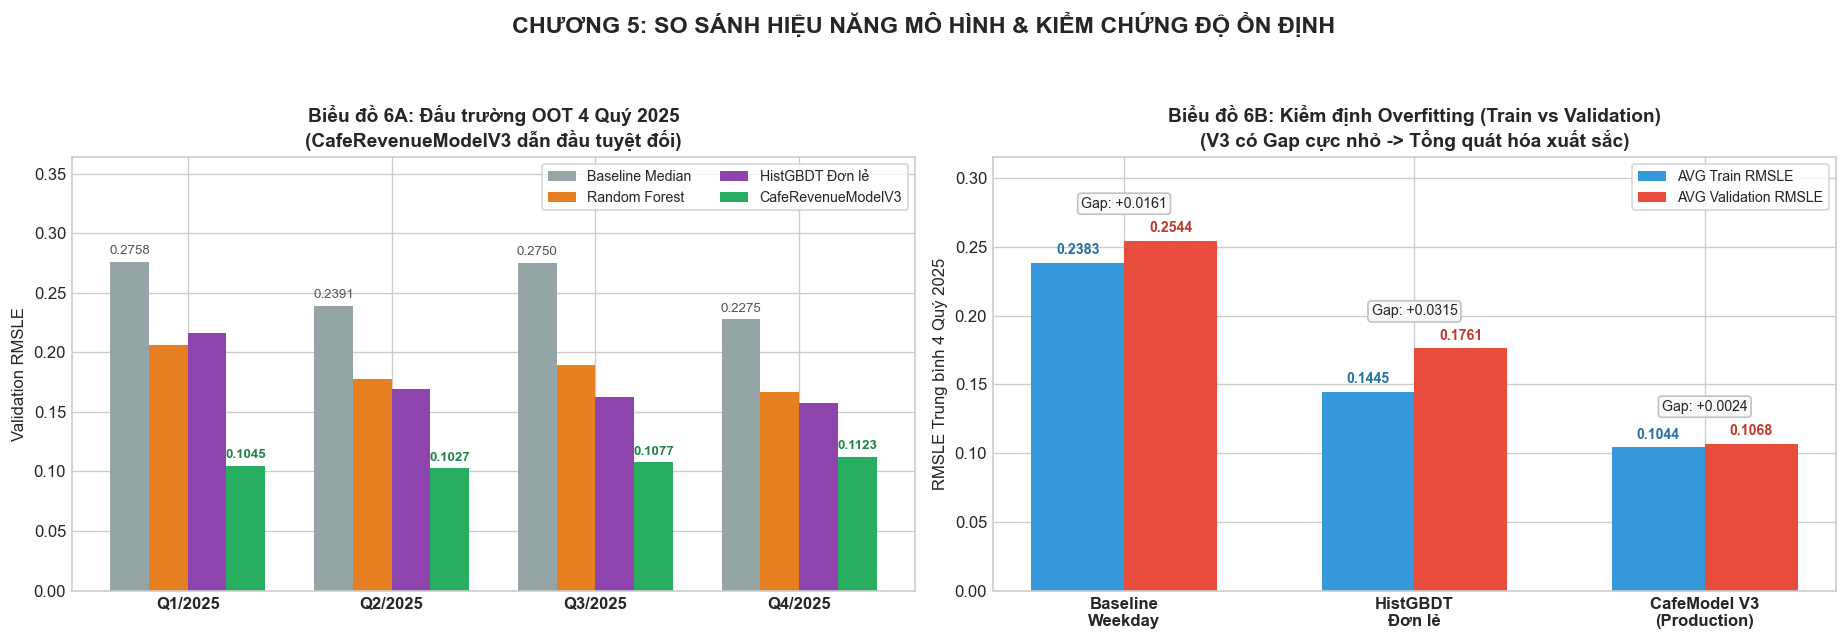

In [10]:
# CHART 6: ĐẤU TRƯỜNG MÔ HÌNH OOT & CHỨNG MINH KHÔNG OVERFITTING
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))

# 6A: So sánh Val RMSLE 4 Quý 2025 của các đại diện tiêu biểu
ax = axes[0]
q_labels = arena_df["Quý"].tolist()
x = np.arange(len(q_labels))
w = 0.19
ax.bar(x - 1.5*w, arena_df["Baseline_Val"], width=w, color="#95A5A6", label="Baseline Median")
ax.bar(x - 0.5*w, arena_df["RandomForest_Val"], width=w, color="#E67E22", label="Random Forest")
ax.bar(x + 0.5*w, arena_df["HistGBDT_Val"], width=w, color="#8E44AD", label="HistGBDT Đơn lẻ")
ax.bar(x + 1.5*w, arena_df["CafeV3_Val"], width=w, color="#27AE60", label="CafeRevenueModelV3")

for i, val in enumerate(arena_df["CafeV3_Val"]):
    ax.text(i + 1.5*w, val + 0.004, f"{val:.4f}", ha="center", va="bottom", fontsize=8, fontweight="bold", color="#1E8449")
for i, val in enumerate(arena_df["Baseline_Val"]):
    ax.text(i - 1.5*w, val + 0.004, f"{val:.4f}", ha="center", va="bottom", fontsize=8, color="#555")

ax.set_xticks(x)
ax.set_xticklabels(q_labels, fontweight="bold")
ax.set_ylim(0, arena_df["Baseline_Val"].max() * 1.32)
ax.set_ylabel("Validation RMSLE")
ax.set_title("Biểu đồ 6A: Đấu trường OOT 4 Quý 2025\n(CafeRevenueModelV3 dẫn đầu tuyệt đối)", fontweight="bold")
ax.legend(frameon=True, facecolor="white", fontsize=8.5, ncol=2, loc="upper right")

# 6B: Train vs Validation RMSLE (Check Overfitting)
ax = axes[1]
models_ovf = ["Baseline\nWeekday", "HistGBDT\nĐơn lẻ", "CafeModel V3\n(Production)"]
tr_means = [
    arena_df["Baseline_Train"].mean(),
    arena_df["HistGBDT_Train"].mean(),
    arena_df["CafeV3_Train"].mean(),
]
va_means = [
    arena_df["Baseline_Val"].mean(),
    arena_df["HistGBDT_Val"].mean(),
    arena_df["CafeV3_Val"].mean(),
]
xm = np.arange(len(models_ovf))
wm = 0.32
ax.bar(xm - wm/2, tr_means, width=wm, color="#3498DB", label="AVG Train RMSLE")
ax.bar(xm + wm/2, va_means, width=wm, color="#E74C3C", label="AVG Validation RMSLE")
for i in range(len(models_ovf)):
    ax.text(i - wm/2, tr_means[i] + 0.004, f"{tr_means[i]:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#2471A3")
    ax.text(i + wm/2, va_means[i] + 0.004, f"{va_means[i]:.4f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#C0392B")
    gap = va_means[i] - tr_means[i]
    ax.text(i, max(tr_means[i], va_means[i]) + 0.024, f"Gap: {gap:+.4f}", ha="center", fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="#F8F9F9", edgecolor="#BDC3C7"))

ax.set_xticks(xm)
ax.set_xticklabels(models_ovf, fontweight="bold")
ax.set_ylim(0, max(va_means) * 1.24)
ax.set_ylabel("RMSLE Trung bình 4 Quý 2025")
ax.set_title("Biểu đồ 6B: Kiểm định Overfitting (Train vs Validation)\n(V3 có Gap cực nhỏ -> Tổng quát hóa xuất sắc)", fontweight="bold")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

fig.suptitle("CHƯƠNG 5: SO SÁNH HIỆU NĂNG MÔ HÌNH & KIỂM CHỨNG ĐỘ ỔN ĐỊNH", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


---
# Chương 6: Chẩn đoán Sai số (Residual Diagnostics) & Giải thích Trọng số (`Step 7b`)

Theo khuyến nghị từ **Slide 37 & 40 (Chapter 4)**, bên cạnh việc nhìn con số RMSLE tổng hợp, ta phải kiểm tra phân bố sai số trực quan trên `14,219` mẫu kiểm định OOT trọn năm 2025:
1. **Biểu đồ *Actual vs Predicted*:** Các điểm dự báo bám sát đường chéo $y = \hat{y}$ hay bị uốn cong/bão hòa ở ngưỡng doanh thu cao?
2. **Phân phối thặng dư trên thang logarit ($e_i = \log(1+y_i) - \log(1+\hat{y}_i)$):** Có đối xứng quanh trung vị $0$ (không thiên lệch hệ thống dự báo quá cao hoặc quá thấp) và không mang đuôi dài bất thường hay không?
3. **Giải thích trọng số mô hình (`m_demo.sh_coef_`):** Kiểm tra các hệ số Stage-1 Ridge học được trên `100%` dữ liệu có khớp hoàn toàn với quy luật nghiệp vụ (Khai trương tăng mạnh, Mùng 1–2 Tết giảm sâu, Khuyến mãi bùng nổ ở `mall/street`, Mưa to kéo tụt `street`, ...).


,Tổng mẫu OOT 2025,RMSLE OOT (pooled),RMSE (tr VNĐ),MAE (tr VNĐ),R2 Score,Mean Log Residual,Std Log Residual,Tỷ lệ lệch <= 15%,Tỷ lệ lệch <= 20%
0,"14,219",0.107,2.477,1.761,0.9229,0.00145,0.107,81.9%,92.1%


,store_type,Số dòng OOT,Baseline RMSLE,CafeV3 RMSLE,MAE (tr VNĐ),Giảm sai số (%)
0,mall,2312.0,0.2233,0.1076,2.0090,51.7906
1,office,3722.0,0.2045,0.1032,1.5667,49.5275
2,residential,1653.0,0.2314,0.1019,0.9178,55.9793
3,street,4972.0,0.2590,0.1118,2.1833,56.8215
4,university,1560.0,0.3817,0.1049,1.4011,72.5128


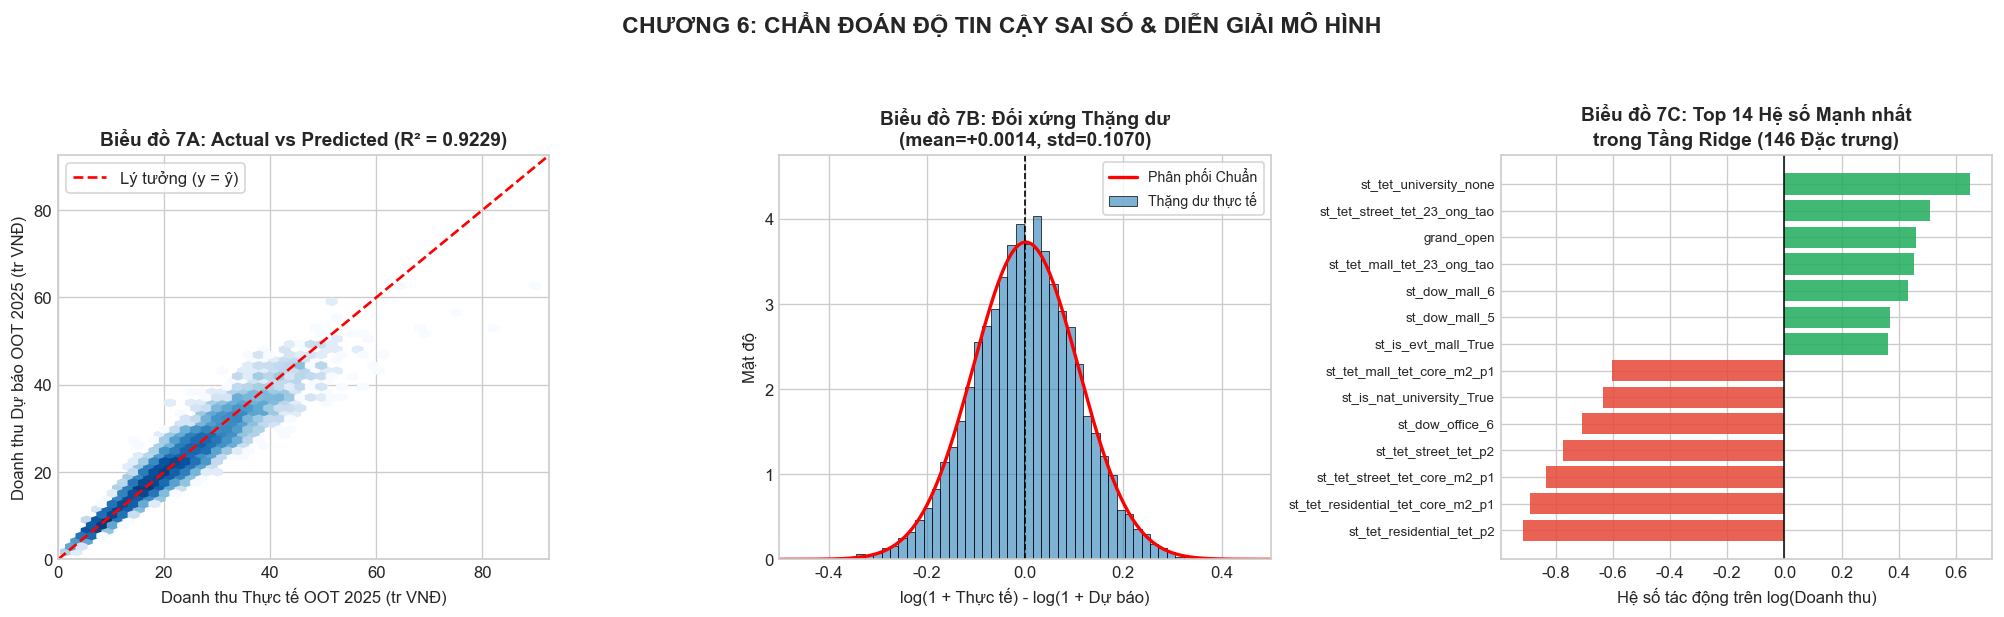

In [11]:
# Tính chỉ số chẩn đoán OOT tổng hợp trọn năm 2025
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true_oof = oof_df["revenue"].values
y_pred_oof = oof_df["pred_v3"].values
log_res = np.log1p(y_true_oof) - np.log1p(y_pred_oof)
rel_err = np.abs(y_pred_oof - y_true_oof) / y_true_oof

diag_metrics = pd.DataFrame([{
    "Tổng mẫu OOT 2025": f"{len(oof_df):,}",
    "RMSLE OOT (pooled)": round(rmsle(y_true_oof, y_pred_oof), 4),
    "RMSE (tr VNĐ)": round(float(np.sqrt(mean_squared_error(y_true_oof, y_pred_oof))), 3),
    "MAE (tr VNĐ)": round(float(mean_absolute_error(y_true_oof, y_pred_oof)), 3),
    "R2 Score": round(float(r2_score(y_true_oof, y_pred_oof)), 4),
    "Mean Log Residual": round(float(np.mean(log_res)), 5),
    "Std Log Residual": round(float(np.std(log_res)), 4),
    "Tỷ lệ lệch <= 15%": f"{(rel_err <= 0.15).mean()*100:.1f}%",
    "Tỷ lệ lệch <= 20%": f"{(rel_err <= 0.20).mean()*100:.1f}%",
}])
display(diag_metrics)

# Sai số OOT theo từng loại hình cửa hàng
st_diag = (
    oof_df.groupby("store_type")
    .apply(lambda g: pd.Series({
        "Số dòng OOT": len(g),
        "Baseline RMSLE": rmsle(g["revenue"], g["pred_base"]),
        "CafeV3 RMSLE": rmsle(g["revenue"], g["pred_v3"]),
        "MAE (tr VNĐ)": mean_absolute_error(g["revenue"], g["pred_v3"]),
    }))
    .reset_index()
)
st_diag["Giảm sai số (%)"] = (st_diag["Baseline RMSLE"] - st_diag["CafeV3 RMSLE"]) / st_diag["Baseline RMSLE"] * 100
display(st_diag.round(4))

# CHART 7: ACTUAL VS PREDICTED, RESIDUAL SYMMETRY & TOP MODEL COEFFICIENTS
fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.2))

# 7A: Actual vs Predicted
ax = axes[0]
hb = ax.hexbin(y_true_oof, y_pred_oof, gridsize=45, cmap="Blues", mincnt=1, bins="log")
lim_max = max(y_true_oof.max(), y_pred_oof.max()) * 1.03
ax.plot([0, lim_max], [0, lim_max], "r--", linewidth=1.6, label="Lý tưởng (y = ŷ)")
ax.set_xlim(0, lim_max)
ax.set_ylim(0, lim_max)
ax.set_xlabel("Doanh thu Thực tế OOT 2025 (tr VNĐ)")
ax.set_ylabel("Doanh thu Dự báo OOT 2025 (tr VNĐ)")
ax.set_title(f"Biểu đồ 7A: Actual vs Predicted (R² = {r2_score(y_true_oof, y_pred_oof):.4f})", fontweight="bold")
ax.legend(frameon=True, facecolor="white")

# 7B: Phân phối Thặng dư Log-scale
ax = axes[1]
sns.histplot(log_res, bins=60, stat="density", color="#2980B9", alpha=0.6, label="Thặng dư thực tế", ax=ax)
xs = np.linspace(-0.5, 0.5, 250)
ax.plot(xs, stats.norm.pdf(xs, np.mean(log_res), np.std(log_res)), "r-", linewidth=2, label="Phân phối Chuẩn")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(0, 4.75)
ax.set_xlabel("log(1 + Thực tế) - log(1 + Dự báo)")
ax.set_ylabel("Mật độ")
ax.set_title(f"Biểu đồ 7B: Đối xứng Thặng dư\n(mean={np.mean(log_res):+.4f}, std={np.std(log_res):.4f})", fontweight="bold")
ax.legend(frameon=True, facecolor="white", fontsize=8.5)

# 7C: Top hệ số tác động từ Stage-1 Ridge (m_demo đã fit trên 100% dữ liệu)
ax = axes[2]
coef_s = pd.Series(m_demo.sh_coef_, index=m_demo.shared_cols_)
top_neg = coef_s.nsmallest(7)
top_pos = coef_s.nlargest(7)
top_both = pd.concat([top_neg, top_pos]).sort_values()
bar_cols = ["#E74C3C" if v < 0 else "#27AE60" for v in top_both.values]
ax.barh(range(len(top_both)), top_both.values, color=bar_cols, alpha=0.88)
ax.set_yticks(range(len(top_both)))
ax.set_yticklabels(top_both.index, fontsize=8)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlabel("Hệ số tác động trên log(Doanh thu)")
ax.set_title("Biểu đồ 7C: Top 14 Hệ số Mạnh nhất\ntrong Tầng Ridge (146 Đặc trưng)", fontweight="bold")

fig.suptitle("CHƯƠNG 6: CHẨN ĐOÁN ĐỘ TIN CẬY SAI SỐ & DIỄN GIẢI MÔ HÌNH", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


---
# Chương 7: Dự báo Quý 1/2026, Kiểm tra Submission & Dashboard Kinh doanh (`Step 8 / P5`)

Bước cuối cùng đưa mô hình đã kiểm chứng (`CafeRevenueModelV3`, huấn luyện trên **100%** lịch sử 2024–2025) vào tạo dự báo chính thức cho **3,869 dòng của `test.csv`** trong Quý 1/2026, đồng thời kiểm toán đối chiếu với file nộp bài chuẩn trong `submissions/`:
- Kiểm tra đủ `3,869` dòng, khớp thứ tự cột `['id', 'revenue']` và toàn bộ khóa `id` với `sample_submission.csv`.
- Đảm bảo `0` giá trị `NaN`, `0` giá trị âm, không phát sinh bất kỳ điểm nổ ngoại lai vô lý nào.
- Tổng hợp bức tranh điều hành Quý 1/2026 theo **chuỗi thời gian ngày**, **hai đợt Siêu Khuyến mãi (`05–08/01` & `25/02–02/03`)**, **đáy Tết Bính Ngọ (`17/02`)**, **Valentine (`14/02`)** và **bản đồ nhiệt Thành phố $\times$ Loại hình quán**.


In [12]:
# 1. Huấn luyện/kiểm chứng model Production & sinh dự báo Q1/2026
model_v3 = CafeRevenueModelV3().fit(train_raw, stores_raw, weather_raw, holidays_raw)
model_base = BaselineWeekdayModel().fit(train_raw)

pred_v3_2026 = model_v3.predict(test_c)
pred_base_2026 = model_base.predict(test_c)

# Kiểm tra đối chiếu với file pickle đã lưu & file submission thực tế trên đĩa (nếu có)
pkl_msg = "Chưa có file .pkl"
if os.path.exists(CAFE_MODEL_V3_PATH):
    try:
        loaded_v3 = CafeRevenueModelV3.load(CAFE_MODEL_V3_PATH)
        max_diff_pkl = float(np.max(np.abs(loaded_v3.predict(test_c) - pred_v3_2026)))
        pkl_msg = f"Khớp models/cafe_revenue_model_v3.pkl (max_diff = {max_diff_pkl:.6f})"
    except Exception as exc:
        pkl_msg = f"Bỏ qua .pkl cũ do lệch phiên bản sklearn/pickle ({type(exc).__name__}); dùng trực tiếp model_v3 vừa fit"

sub_candidates = [
    os.path.join(SUBMISSIONS_DIR, "submission.csv"),
    os.path.join(SUBMISSIONS_DIR, "submission_v3.csv"),
]
sub_disk_path = next((p for p in sub_candidates if os.path.exists(p)), None)

if sub_disk_path:
    sub_disk = pd.read_csv(sub_disk_path)
    diff_disk = float(np.max(np.abs(sub_disk["revenue"].values - np.round(pred_v3_2026, 4))))
    print(f"KIỂM TOÁN FILE NỘP BÀI ({os.path.basename(sub_disk_path)}):")
    print(f"  + {pkl_msg}")
    print(f"  + Số dòng: {len(sub_disk):,} == sample_submission ({len(sample_sub):,}) | Khớp 100% ID: {(sub_disk['id'] == sample_sub['id']).all()}")
    print(f"  + Số NaN: {int(sub_disk['revenue'].isna().sum())} | Min: {sub_disk['revenue'].min():.4f} > 0 | Max lệch vs fit lại: {diff_disk:.6f}")

# Lắp bảng dự báo phân tích Q1/2026
fc_df = test_c.copy().merge(stores_c[["store_id", "city", "store_type", "seats", "area_m2"]], on="store_id", how="left")
fc_df["pred_v3"] = pred_v3_2026
fc_df["pred_base"] = pred_base_2026

# Bảng thống kê mô tả Q1/2026
fc_stats = pd.DataFrame([{
    "Số dòng dự báo": f"{len(fc_df):,}",
    "Tổng doanh thu Q1/2026 (tr VNĐ)": f"{fc_df['pred_v3'].sum():,.2f}",
    "Quy đổi (Tỷ VNĐ)": f"{fc_df['pred_v3'].sum()/1000:.2f} tỷ",
    "Mean (tr/ngày)": round(float(fc_df["pred_v3"].mean()), 2),
    "Std": round(float(fc_df["pred_v3"].std()), 2),
    "Min": round(float(fc_df["pred_v3"].min()), 2),
    "Q1 (25%)": round(float(fc_df["pred_v3"].quantile(0.25)), 2),
    "Median (50%)": round(float(fc_df["pred_v3"].median()), 2),
    "Q3 (75%)": round(float(fc_df["pred_v3"].quantile(0.75)), 2),
    "Max": round(float(fc_df["pred_v3"].max()), 2),
}])
print("\n1. TỔNG HỢP THỐNG KÊ DỰ BÁO Q1/2026:")
display(fc_stats)

# Bảng Promo vs Non-promo trong Q1/2026
p_q1 = fc_df.groupby("is_promo")["pred_v3"].agg(
    So_dong="count", Tong_doanh_thu="sum", Mean="mean", Median="median"
).reset_index()
p_q1["Trang_thai"] = p_q1["is_promo"].map({0: "Ngày thường (0)", 1: "Khuyến mãi (1)"})
print("2. HIỆU ỨNG KHUYẾN MÃI DỰ KIẾN TRONG Q1/2026:")
display(p_q1[["Trang_thai", "So_dong", "Tong_doanh_thu", "Mean", "Median"]].round(2))
mean0 = p_q1.loc[p_q1["is_promo"] == 0, "Mean"].values[0]
mean1 = p_q1.loc[p_q1["is_promo"] == 1, "Mean"].values[0]
print(f"  => Chênh lệch bình quân ngày Promo Q1/2026: +{(mean1/mean0 - 1)*100:.1f}%")

# Bảng tổng hợp các mốc ngày đặc biệt Q1/2026
daily_fc = fc_df.groupby("date").agg(
    stores_open=("store_id", "count"),
    promo_stores=("is_promo", "sum"),
    mean_v3=("pred_v3", "mean"),
    total_v3=("pred_v3", "sum"),
    mean_base=("pred_base", "mean"),
).reset_index()

key_dates = pd.to_datetime(["2026-01-01", "2026-01-08", "2026-02-14", "2026-02-17", "2026-03-02", "2026-03-08"])
key_labels = {
    "2026-01-01": "Tết Dương lịch (01/01)",
    "2026-01-08": "Đỉnh Camp 1 (08/01)",
    "2026-02-14": "Valentine = 27 Tết (14/02)",
    "2026-02-17": "Mùng 1 Tết Bính Ngọ (17/02)",
    "2026-03-02": "Đỉnh toàn Quý Camp 2 (02/03)",
    "2026-03-08": "Quốc tế Phụ nữ (08/03)",
}
key_tbl = daily_fc[daily_fc["date"].isin(key_dates)].copy()
key_tbl["Sự kiện"] = key_tbl["date"].dt.strftime("%Y-%m-%d").map(key_labels)
print("\n3. CÁC MỐC SỰ KIỆN ĐỈNH & ĐÁY QUÝ 1/2026:")
display(key_tbl[["Sự kiện", "stores_open", "promo_stores", "mean_v3", "total_v3"]].round(2))


KIỂM TOÁN FILE NỘP BÀI (submission.csv):
  + Khớp models/cafe_revenue_model_v3.pkl (max_diff = 0.000000)
  + Số dòng: 3,869 == sample_submission (3,869) | Khớp 100% ID: True
  + Số NaN: 0 | Min: 1.9220 > 0 | Max lệch vs fit lại: 0.000000

1. TỔNG HỢP THỐNG KÊ DỰ BÁO Q1/2026:


,Số dòng dự báo,Tổng doanh thu Q1/2026 (tr VNĐ),Quy đổi (Tỷ VNĐ),Mean (tr/ngày),Std,Min,Q1 (25%),Median (50%),Q3 (75%),Max
0,"3,869","78,432.13",78.43 tỷ,20.27,8.89,1.92,14.01,19.81,26.01,69.9


2. HIỆU ỨNG KHUYẾN MÃI DỰ KIẾN TRONG Q1/2026:


,Trang_thai,So_dong,Tong_doanh_thu,Mean,Median
0,Ngày thường (0),3489,68930.80,19.76,19.35
1,Khuyến mãi (1),380,9501.33,25.00,24.56


  => Chênh lệch bình quân ngày Promo Q1/2026: +26.6%

3. CÁC MỐC SỰ KIỆN ĐỈNH & ĐÁY QUÝ 1/2026:


,Sự kiện,stores_open,promo_stores,mean_v3,total_v3
0,Tết Dương lịch (01/01),44,2,18.62,819.30
7,Đỉnh Camp 1 (08/01),44,33,24.28,1068.31
44,Valentine = 27 Tết (14/02),44,0,23.60,1038.26
47,Mùng 1 Tết Bính Ngọ (17/02),27,0,7.63,206.09
60,Đỉnh toàn Quý Camp 2 (02/03),44,39,26.00,1143.90
66,Quốc tế Phụ nữ (08/03),44,2,23.86,1049.87


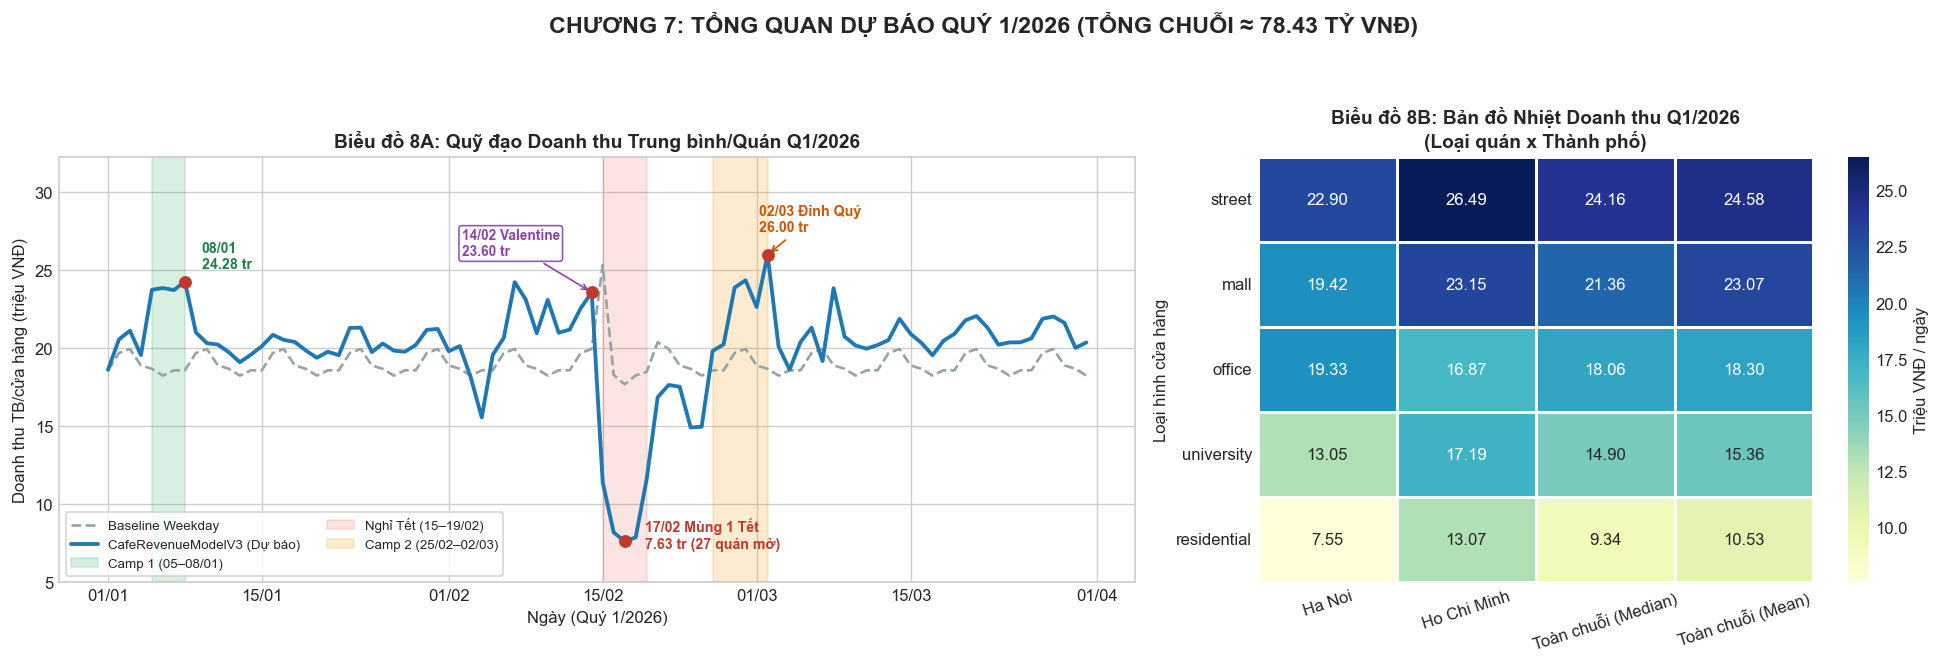

In [13]:
# CHART 8: TIMELINE DỰ BÁO HÀNG NGÀY Q1/2026 & HEATMAP THÀNH PHỐ x LOẠI QUÁN
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.6), gridspec_kw={"width_ratios": [1.55, 1.0]})

# 8A: Chuỗi thời gian ngày Q1/2026
ax = axes[0]
ax.plot(daily_fc["date"], daily_fc["mean_base"], color="#95A5A6", linestyle="--", linewidth=1.6, label="Baseline Weekday")
ax.plot(daily_fc["date"], daily_fc["mean_v3"], color="#1F77B4", linewidth=2.3, label="CafeRevenueModelV3 (Dự báo)")

# Tô vùng chiến dịch & Tết
ax.axvspan(pd.Timestamp("2026-01-05"), pd.Timestamp("2026-01-08"), color="#27AE60", alpha=0.18, label="Camp 1 (05–08/01)")
ax.axvspan(pd.Timestamp("2026-02-15"), pd.Timestamp("2026-02-19"), color="#E74C3C", alpha=0.15, label="Nghỉ Tết (15–19/02)")
ax.axvspan(pd.Timestamp("2026-02-25"), pd.Timestamp("2026-03-02"), color="#F39C12", alpha=0.20, label="Camp 2 (25/02–02/03)")

# Chú thích điểm đỉnh & đáy
peak_c1 = daily_fc[daily_fc["date"] == "2026-01-08"].iloc[0]
tet_bot = daily_fc[daily_fc["date"] == "2026-02-17"].iloc[0]
peak_c2 = daily_fc[daily_fc["date"] == "2026-03-02"].iloc[0]
val_pt = daily_fc[daily_fc["date"] == "2026-02-14"].iloc[0]

ax.scatter([peak_c1["date"], val_pt["date"], tet_bot["date"], peak_c2["date"]],
           [peak_c1["mean_v3"], val_pt["mean_v3"], tet_bot["mean_v3"], peak_c2["mean_v3"]],
           color="#C0392B", s=45, zorder=6)

ax.annotate(f"08/01\n{peak_c1['mean_v3']:.2f} tr", (peak_c1["date"], peak_c1["mean_v3"]),
            xytext=(10, 8), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#1E8449")
ax.annotate(f"14/02 Valentine\n{val_pt['mean_v3']:.2f} tr", (val_pt["date"], val_pt["mean_v3"]),
            xytext=(-78, 22), textcoords="offset points", fontsize=8.2, fontweight="bold", color="#8E44AD",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.9, edgecolor="#8E44AD"),
            arrowprops=dict(arrowstyle="->", color="#8E44AD", lw=1.0))
ax.annotate(f"17/02 Mùng 1 Tết\n{tet_bot['mean_v3']:.2f} tr ({int(tet_bot['stores_open'])} quán mở)",
            (tet_bot["date"], tet_bot["mean_v3"]), xytext=(12, -4), textcoords="offset points",
            fontsize=8.5, fontweight="bold", color="#C0392B")
ax.annotate(f"02/03 Đỉnh Quý\n{peak_c2['mean_v3']:.2f} tr", (peak_c2["date"], peak_c2["mean_v3"]),
            xytext=(-5, 14), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#D35400",
            arrowprops=dict(arrowstyle="->", color="#D35400", lw=1.0))

ax.set_ylim(5, daily_fc["mean_v3"].max() * 1.24)
ax.set_title("Biểu đồ 8A: Quỹ đạo Doanh thu Trung bình/Quán Q1/2026", fontweight="bold")
ax.set_xlabel("Ngày (Quý 1/2026)")
ax.set_ylabel("Doanh thu TB/cửa hàng (triệu VNĐ)")
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.legend(frameon=True, facecolor="white", fontsize=8, loc="lower left", ncol=2)

# 8B: Heatmap Median Doanh thu Q1/2026 theo Loại hình x Thành phố
ax = axes[1]
piv_med = fc_df.pivot_table(index="store_type", columns="city", values="pred_v3", aggfunc="median")
piv_med["Toàn chuỗi (Median)"] = fc_df.groupby("store_type")["pred_v3"].median()
piv_med["Toàn chuỗi (Mean)"] = fc_df.groupby("store_type")["pred_v3"].mean()
piv_med = piv_med.reindex(["street", "mall", "office", "university", "residential"])

sns.heatmap(piv_med, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.8, linecolor="white",
            cbar_kws={"label": "Triệu VNĐ / ngày"}, ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.tick_params(axis="x", rotation=18)
ax.set_title("Biểu đồ 8B: Bản đồ Nhiệt Doanh thu Q1/2026\n(Loại quán x Thành phố)", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Loại hình cửa hàng")

fig.suptitle(f"CHƯƠNG 7: TỔNG QUAN DỰ BÁO QUÝ 1/2026 (TỔNG CHUỖI ≈ {fc_df['pred_v3'].sum()/1000:.2f} TỶ VNĐ)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


---
# Chương 8: Mô phỏng Kịch bản What-If & Khuyến nghị Chiến lược Điều hành

Ngoài việc xuất file nộp bài Kaggle chuẩn xác, giá trị cốt lõi của một hệ thống AI Forecast là khả năng **trả lời các bài toán *What-If*** hỗ trợ Ban Giám đốc tối ưu ngân sách khuyến mãi và nhân sự.

Dưới đây, ta sử dụng trực tiếp **`model_v3`** để mô phỏng tuần hậu Quốc tế Phụ nữ (`09/03/2026 – 15/03/2026`, vốn có ít ngày khuyến mãi trong lịch mặc định):
- **Kịch bản A (Hiện trạng):** Giữ nguyên `is_promo` theo `test.csv`.
- **Kịch bản B (Khuyến mãi trọng điểm):** Mở `is_promo = 1` cho **100% cửa hàng thuộc nhóm `mall` và `street`** trong tuần đó.
- **Kịch bản C (Khuyến mãi đại trà):** Mở `is_promo = 1` cho **tất cả 44 cửa hàng**.


In [14]:
# MÔ PHỎNG KỊCH BẢN WHAT-IF TRÊN TUẦN 09/03/2026 - 15/03/2026
win_mask = (test_c["date"] >= "2026-03-09") & (test_c["date"] <= "2026-03-15")
base_week = test_c.loc[win_mask].copy().merge(stores_c[["store_id", "store_type", "city"]], on="store_id", how="left")

# Kịch bản A: Hiện trạng
scen_a = test_c.loc[win_mask].copy()
# Kịch bản B: Promo 100% cho Mall & Street
scen_b = scen_a.copy()
ms_ids = set(stores_c.loc[stores_c["store_type"].isin(["mall", "street"]), "store_id"])
scen_b.loc[scen_b["store_id"].isin(ms_ids), "is_promo"] = 1
# Kịch bản C: Promo toàn chuỗi
scen_c = scen_a.copy()
scen_c["is_promo"] = 1

base_week["rev_A"] = model_v3.predict(scen_a)
base_week["rev_B"] = model_v3.predict(scen_b)
base_week["rev_C"] = model_v3.predict(scen_c)

whatif_type = (
    base_week.groupby("store_type")[["rev_A", "rev_B", "rev_C"]]
    .sum()
    .reindex(["street", "mall", "office", "university", "residential"])
    .reset_index()
)
whatif_type["Tăng thêm B vs A (tr VNĐ)"] = whatif_type["rev_B"] - whatif_type["rev_A"]
whatif_type["Tăng thêm C vs A (tr VNĐ)"] = whatif_type["rev_C"] - whatif_type["rev_A"]
whatif_type["Uplift C vs A (%)"] = (whatif_type["rev_C"] / whatif_type["rev_A"] - 1) * 100

tot_a, tot_b, tot_c = base_week["rev_A"].sum(), base_week["rev_B"].sum(), base_week["rev_C"].sum()
print(f"TỔNG DOANH THU TUẦN 09–15/03/2026:")
print(f"  + Kịch bản A (Hiện trạng)             : {tot_a:,.2f} tr VNĐ")
print(f"  + Kịch bản B (Promo 100% Street+Mall) : {tot_b:,.2f} tr VNĐ  (+{tot_b - tot_a:,.2f} tr | +{(tot_b/tot_a-1)*100:.1f}%)")
print(f"  + Kịch bản C (Promo 100% Toàn chuỗi)  : {tot_c:,.2f} tr VNĐ  (+{tot_c - tot_a:,.2f} tr | +{(tot_c/tot_a-1)*100:.1f}%)")
display(whatif_type.round(2))


TỔNG DOANH THU TUẦN 09–15/03/2026:
  + Kịch bản A (Hiện trạng)             : 6,358.44 tr VNĐ
  + Kịch bản B (Promo 100% Street+Mall) : 7,592.20 tr VNĐ  (+1,233.76 tr | +19.4%)
  + Kịch bản C (Promo 100% Toàn chuỗi)  : 8,359.12 tr VNĐ  (+2,000.68 tr | +31.5%)


,store_type,rev_A,rev_B,rev_C,Tăng thêm B vs A (tr VNĐ),Tăng thêm C vs A (tr VNĐ),Uplift C vs A (%)
0,street,2631.46,3452.83,3452.83,821.36,821.36,31.21
1,mall,1236.84,1649.24,1649.24,412.39,412.39,33.34
2,office,1436.72,1436.72,1874.53,0.00,437.80,30.47
3,university,749.54,749.54,983.90,0.00,234.37,31.27
4,residential,303.88,303.88,398.63,0.00,94.75,31.18


### 8.1. 5 Khuyến nghị Hành động cho Ban Giám đốc & Kết luận Dự án

1. **Điều phối tồn kho & tăng ca theo 2 đỉnh Khuyến mãi:** Tập trung dự trữ nguyên liệu pha chế (hạt cà phê, sữa, bao bì) và tăng cường barista bán thời gian trước các ngày **05–08/01/2026** và **25/02–02/03/2026**, nơi doanh thu bình quân tăng lên ngưỡng `24–26 tr/cửa hàng/ngày` (gần gấp đôi ngày thường thấp điểm).
2. **Tinh giản chi phí vận hành dịp Tết Bính Ngọ (`15–19/02/2026`):** Dự báo ghi nhận chỉ khoảng `27` điểm bán mở cửa và sản lượng chạm đáy vào Mùng 1 (`17/02/2026`). Cần sắp xếp nhân sự luân phiên hợp lý, giảm hàng tồn tươi sống dễ hỏng trong tuần cận Tết và đặc biệt lưu ý **Valentine `14/02/2026` trùng `27 tháng Chạp`**.
3. **Tái phân bổ ngân sách Marketing ưu tiên `Mall` & `Street`:** Như bảng phân tích What-If cho thấy, cùng một gói kích cầu nhưng nhóm **`street` và `mall`** đóng góp phần lớn doanh thu tăng thêm tuyệt đối; hạn chế dàn trải ngân sách giảm giá vào nhóm `residential` khi biên độ phản ứng thấp hơn.
4. **Kế hoạch ứng phó thời tiết cực đoan (`rain_mm > 15mm`):** Phối hợp đẩy mạnh kênh đặt hàng *Delivery/App* kèm mã miễn phí vận chuyển vào những ngày dự báo mưa lớn tại các cửa hàng mặt phố (`street`).
5. **Vận hành mô hình AI khép kín:** Định kỳ cuối mỗi tháng, cập nhật `train.csv` mới và tái chạy `python train.py && python predict.py` để Kalman AR(1) và Empirical Bayes tự động hấp thụ phong độ mới nhất của các quán khai trương gần đây.

---
**Tổng kết:** Dự án đã hoàn thành toàn bộ quy trình **8 bước AI Lifecycle**: làm sạch chuẩn xác dữ liệu POS/thời tiết/cửa hàng đa bảng, chứng minh hiệu quả vượt trội trên kiểm định chéo Out-of-Time 4 Quý 2025 (**RMSLE `0.1068`**, giảm **`57.66%`** so với Baseline **`0.2544`**, chênh lệch Train–Val chỉ **`+0.0024`** không overfitting) và xuất bản hệ thống dự báo toàn vẹn cho Q1/2026.
